# DES Y3 demonstration: how three-point shear changes IA constraints

A galaxy's observed ellipticity contains gravitational shear and an intrinsic
shape. When neighboring galaxies align with the same tidal field, their
intrinsic shapes correlate with each other and with the matter that lenses
other galaxies, so an intrinsic-alignment (IA) parameter can imitate part of a
cosmological change in a two-point shear correlation. A three-point
measurement weights the matter distribution differently and can separate some
of these parameter responses. This notebook examines that mechanism with
actual predictions and then a joint Fisher forecast.

The calculation keeps 400 two-point and 80 aperture-skewness rows from the
public Y3 simulation files, and it compares the nonlinear-alignment model
(NLA) with tidal alignment and tidal torquing (TATT) while varying $w_0$ and
$w_a$. These are demonstration forecasts, not published DES constraints: the
sources undergo recorded clipping and normalization, the covariance stays
fixed, and the agreement between its measurement weights and the
finite-triangle model is unvalidated.
[EXAMPLE_FISHER_ACCURACY.ipynb](EXAMPLE_FISHER_ACCURACY.ipynb) examines
numerical convergence.

The sequence follows the Roman Fourier and LSST Y1 teaching notebooks:
settings and inputs, physical responses, Fisher construction, and numerical
checks. Expensive cells read matching saved results when they exist and run
the calculation when they are absent.

The source distribution and survey covariance are included inputs in `data/`.
The workflow prepares missing fiducial theory tables in `chains/` before
calculating a Fisher matrix. Saved results there must match the current
configuration; frozen regression predictions belong in `tests/`.


**Model and data.** The settings come from the demonstration workflows and the
saved forecasts the cells below read:

| Choice | Value |
| --- | --- |
| Data vector | 400 $\xi_\pm$ rows and 80 $\langle M_\mathrm{ap}^3\rangle$ rows, with the public Y3 covariance |
| Aperture radii | $R=7,14,25,40$ arcmin; the model integrates triangle sides from $8$ to $80$ arcmin |
| IA fiducial | $(A_1,\eta_1,A_2,\eta_2,b_\mathrm{TA})=(-0.33,2.81,0.65,1.69,0.91)$ at pivot $z_0=0.62$, the TATT point of Gomes et al. (arXiv:2601.09133); NLA keeps $A_1,\eta_1$ with $A_2=b_\mathrm{TA}=0$ |
| Varied parameters | NLA: 17 ($\Omega_m$, $\sigma_8$, $\Omega_b$, $h$, $n_s$, $A_1$, $\eta_1$, $m_{1\ldots4}$, $\Delta z_{1\ldots4}$, $w_0$, $w_a$); TATT: 20 (adding $A_2$, $\eta_2$, $b_\mathrm{TA}$) |
| Gaussian priors | $m_{1\ldots4}$: 0.0091, 0.0078, 0.0076, 0.0076; $\Delta z_{1\ldots4}$: 0.018, 0.015, 0.011, 0.017; none on $w_0$, $w_a$ |
| Derivatives | five-point stencils at spacings $h$ and $h/2$ (103 NLA and 121 TATT mean evaluations) |
| Quadratic IA power | `power_mode=2`: nonlinear $P(k,z)$ at each redshift |
| Angular orders | $L_\mathrm{max}=M_\mathrm{max}=20$ |
| Threads | one BLAS worker; OpenMP capped at four |

Words used throughout:

- The redshift distribution $n_i(z)$ gives the relative number of source
  galaxies in bin $i$ per unit redshift, with integral one.
- $\xi_\pm(\theta)$ are the two-point correlations of two projected shapes at
  separation $\theta$; $\langle M_\mathrm{ap}^3(R)\rangle$ (**Map3**) is the
  skewness of shear integrated with a compensated aperture filter of radius
  $R$.
- **NLA** describes intrinsic alignments with a tidal-alignment amplitude
  $A_1$ and redshift exponent $\eta_1$; **TATT** adds a quadratic tidal
  amplitude $A_2$, its exponent $\eta_2$, and a density-weighting coefficient
  $b_\mathrm{TA}$.
- The **Fisher matrix** is the local Gaussian information of the forecast; a
  **marginalized** error lets every other varied parameter move, while a
  conditional error holds them fixed.
- A **derivative column** is the change of every measurement per unit change
  of one parameter, with the others held fixed.
- **PCHIP** is a shape-preserving cubic interpolation; the source preparation
  uses it to rebuild $n_i(z)$ from processed histogram midpoints.

## 1. Set up Python and the figure style

`nw` contains this project's notebook wrappers. Each expensive operation calls
the command-line driver with a named YAML file, and the wrapper checks reused
predictions against that configuration, the measurement row order, the
covariance, the physical inputs and the implementation files; it refuses
existing files with different settings rather than overwriting them.

The C loops use at most four OpenMP workers. BLAS, which handles the matrix
operations, uses one worker, and the runtime check also covers a reused
notebook kernel, where environment variables alone cannot change an already
loaded BLAS library.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
os.environ["OMP_THREAD_LIMIT"] = "4"
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
import cosmolike_des_3pcf_fisher_wrappers as nw

blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 2. Read the sources and the measurement

The redshift distribution $n_i(z)$ controls both the lensing and the IA
weights. The original simulation FITS has negative midpoint samples; the
preparation step clips them to zero and normalizes each bin by a trapezoidal
integral over the midpoint redshifts. This changes an input file, so the JSON
sidecar records the original and derived file hashes, the removed negative
areas and the normalization factors, and the wrapper verifies the derived FITS
hash before plotting. Clipping is a processing choice, not a source
recalibration, and it brings no uncertainty model with it.

The physical-table preparation interpolates the processed midpoint samples
with a shape-preserving cubic (PCHIP), with zeros at the measured outer edges
and a zero plateau to the background limit. The last source cell ends at
$z=3.0$; extending its nonzero last midpoint toward the background limit
$z=3.1$ would create a populated tail absent from that support. The code
samples the reconstruction on 9601 uniform nodes and normalizes again,
preserving the chosen support rather than each histogram cell probability. The
plotted curves below are the processed native samples, and the
[source study](tests/studies/source_policy_validation.md) compares the
reconstructions and the separate source, kernel and radial grids.

Midpoint integrals: [1. 1. 1. 1.]
Policy: Demonstration Fisher forecast only: replace negative BIN midpoint samples by zero, then divide each bin by the trapezoidal integral of its clipped curve over the supplied Z_MID samples.
Per-bin record: [{'column': 'BIN1', 'negative_area_fraction_of_positive': 0.0004101922963981577, 'negative_area_magnitude': 0.000410360623164525, 'negative_sample_count': 12, 'normalization_factor': 0.9995898077036017, 'original_fits_format': 'D', 'original_positive_integral': 1.0004103606231647, 'original_signed_integral': 1.0, 'output_fits_format': 'D', 'output_midpoint_integral': 0.9999999999999999}, {'column': 'BIN2', 'negative_area_fraction_of_positive': 0.0, 'negative_area_magnitude': 0.0, 'negative_sample_count': 0, 'normalization_factor': 1.0, 'original_fits_format': 'D', 'original_positive_integral': 1.0, 'original_signed_integral': 1.0, 'output_fits_format': 'D', 'output_midpoint_integral': 1.0}, {'column': 'BIN3', 'negative_area_fraction_of_positive':

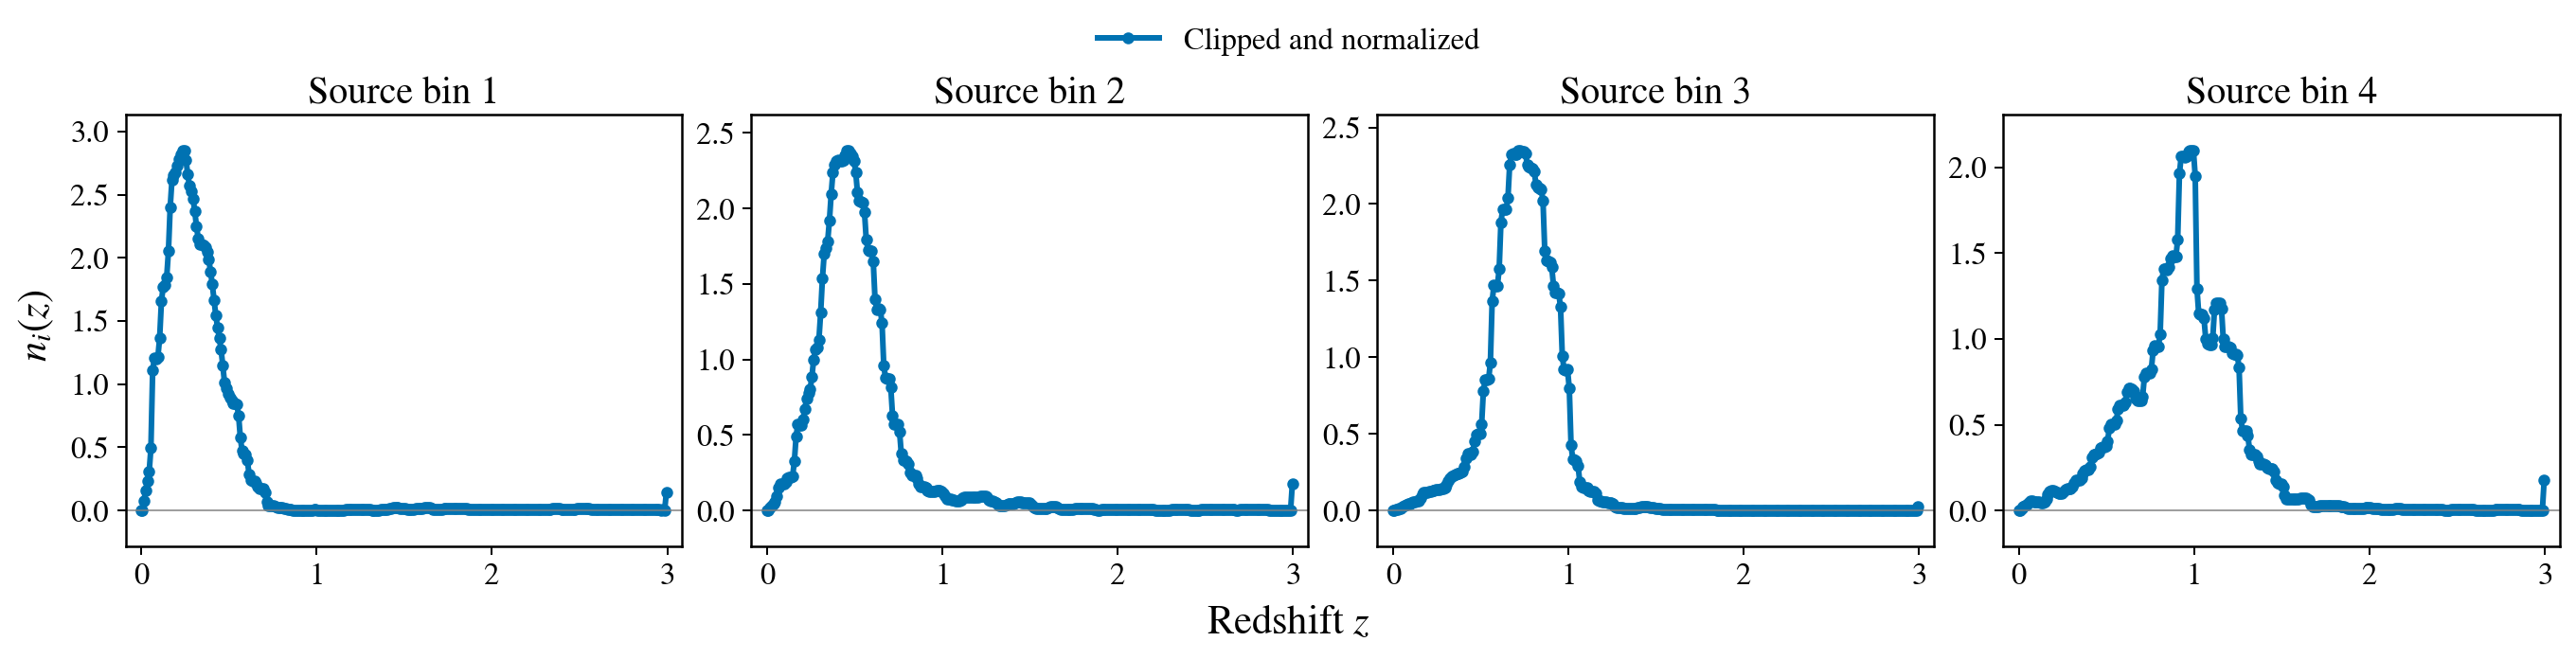

In [3]:
workflows = {
    "nla": nw.demonstration_workflow(model="nla"),
    "tatt": nw.demonstration_workflow(model="tatt"),
}
sources = nw.source_report(workflow=workflows["tatt"])
print("Midpoint integrals:", sources["midpoint_integrals"])
print("Policy:", sources["preprocessing"]["policy"])
print("Per-bin record:", sources["preprocessing"]["bins"])
source_figure, source_axes = nw.plot_sources(report=sources)
plt.show()

The two-point rows are $\xi_+(\theta)$ and $\xi_-(\theta)$, correlations of
two projected shapes at separation $\theta$. The three-point rows are
$\langle M_\mathrm{ap}^3(R)\rangle$, the skewness of shear integrated with a
compensated aperture filter. The aperture radius $R$ differs from the
triangle-side cut behind the moment: here $R=7,14,25,40$ arcmin, while the
model integrates triangle sides from $8$ to $80$ arcmin, and the exact
measurement bins and weights still need matching.

The correlation matrix is $C_{ab}/\sqrt{C_{aa}C_{bb}}$. Its off-diagonal
two-point/three-point rectangle shows why the two Fisher matrices cannot
simply add. The notebook keeps the cross-covariance and all rows, with no
hidden scale selection.

Public source: https://github.com/rchgomes/3pcf_integrator
Revision: d6098d326dcb03bc750adcc9627119f52d928944
File checks: [{'file': 'data/dv/sim_2pt-NLA-cosmoCosmogrid-04Nov24.fits', 'status': 'matches_pinned_blob'}, {'file': 'data/dv/sim_map3_emu-NLA-cosmoCosmogrid-24FEBRUARY2025_WITH_COV.fits', 'status': 'matches_pinned_blob'}, {'file': 'data/covariance/xip_xim_map3_covariance_8ARCMINCUT_25Feb25.fits', 'status': 'matches_pinned_blob'}, {'file': 'config/3pt.ini', 'status': 'matches_pinned_blob'}, {'file': 'config/joint.ini', 'status': 'matches_pinned_blob'}, {'file': 'config/cosmic-shear.ini', 'status': 'matches_pinned_blob'}, {'file': 'config/moped.ini', 'status': 'matches_pinned_blob'}, {'file': 'config/astrophysical.ini', 'status': 'matches_pinned_blob'}, {'file': 'config/cosmo.ini', 'status': 'matches_pinned_blob'}, {'file': 'config/linear-power.ini', 'status': 'matches_pinned_blob'}, {'file': 'config/test-cosmogridc-simdv-joint-2pt-moped-run-796sims-february-Percival/des-y3-shea

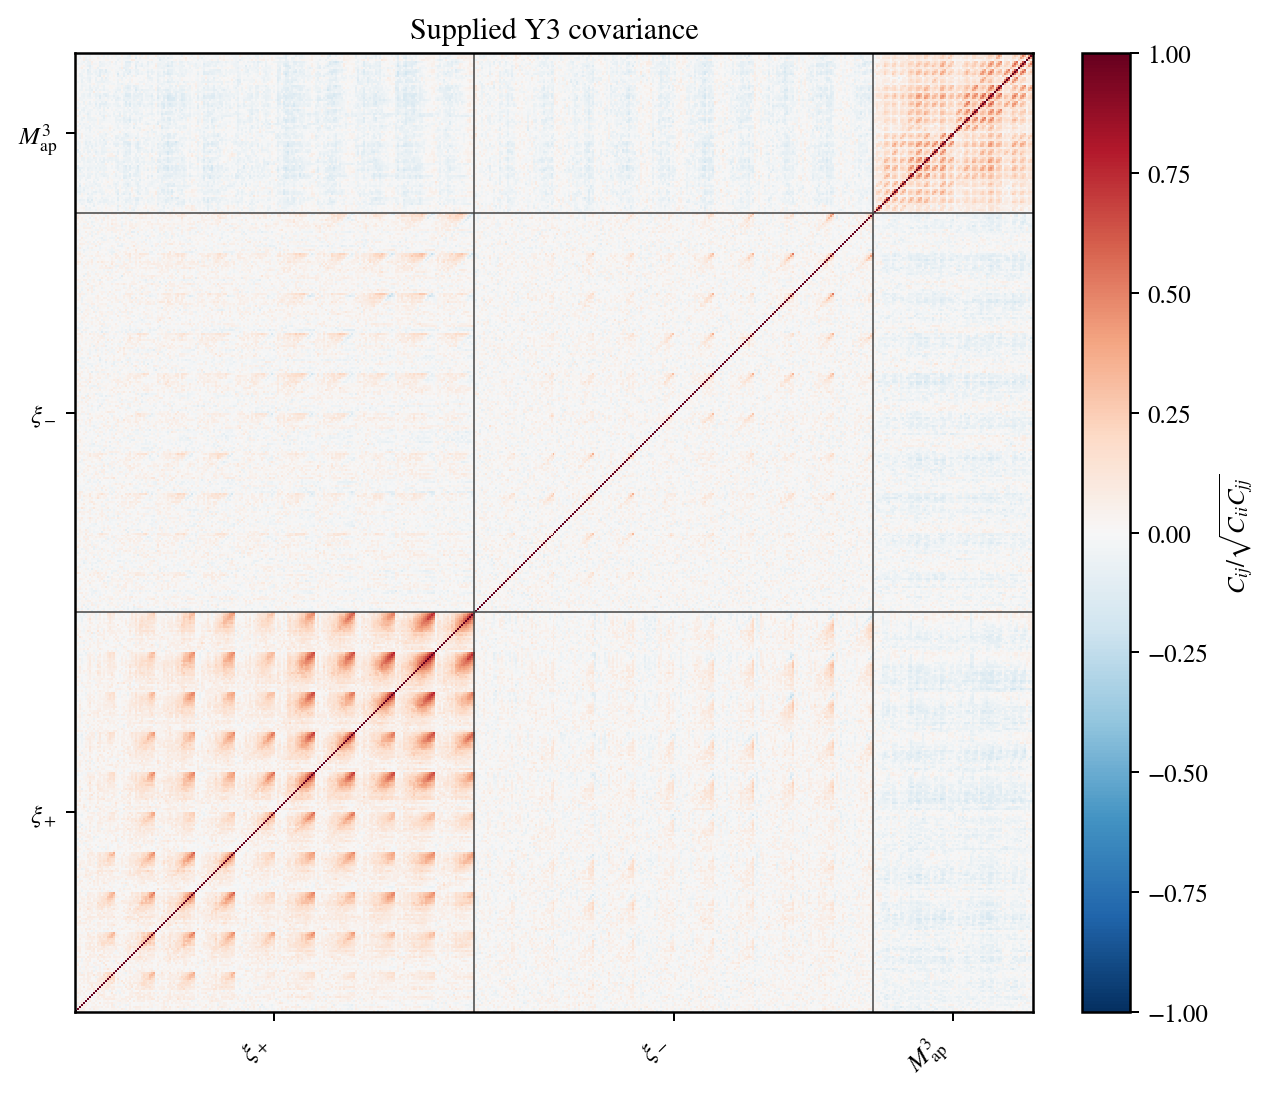

In [4]:
public_inputs = nw.verify_public_inputs()
print("Public source:", public_inputs["repository"])
print("Revision:", public_inputs["commit"])
print("File checks:", public_inputs["files"])
rows, covariance, counts = workflows["tatt"].public_covariance()
print("Rows:", counts, "matrix shape:", covariance.shape)
plots.plot_correlation(
    covariance=covariance,
    labels=("Supplied Y3 covariance", "Reference"),
    block_sizes=[counts["xip"], counts["xim"], counts["map3"]],
    block_labels=[r"$\xi_+$", r"$\xi_-$", r"$M_{\rm ap}^3$"],
)

## 3. Compare actual IA sign responses

NLA uses the tidal-alignment amplitude $A_1$ and redshift exponent $\eta_1$;
TATT adds the quadratic tidal amplitude $A_2$, its exponent $\eta_2$, and the
density-weighting coefficient $b_\mathrm{TA}$. The opposite-sign choices
$(A_1,A_2)=(-0.2,0.4)$ and $(0.2,-0.4)$ follow the question examined in
Figure 9 of [Gomes et al., arXiv:2601.09133](https://arxiv.org/abs/2601.09133);
the NLA comparison instead varies $A_1=\pm0.2$ with $A_2=b_\mathrm{TA}=0$. A
common prediction with both amplitudes zero gives the no-IA reference, and
every case keeps the same cosmology, source model and numerical settings. The
redshift exponents and the power prescription stay those of the TATT
demonstration; the printed parameters make this choice visible. Here
`power_mode=2` uses nonlinear $P(k,z)$ at each redshift in the quadratic
three-point IA terms, while mode 1 uses $P_\mathrm{nl}(k,0)D(z)^2$, with
$D(z)$ the linear growth factor normalized at zero redshift. Choosing between
them changes the physical model; raising the numerical sampling does not make
them equivalent.

The next cell writes five explicit JSON configurations and reads or computes
actual $\xi_\pm$ and finite-triangle $M_\mathrm{ap}^3$ predictions. Each model
shows three curves, including the common no-IA reference, and four source
auto-bin groups appear for legibility while all cross-bin rows enter the later
distance and Fisher calculations. The test covers the response mechanism, not
an absolute reproduction of Figure 9: the estimator weights and the starting
$L_\mathrm{max}=M_\mathrm{max}=20$ differ from the paper's
$L_\mathrm{max}=50$, $M_\mathrm{max}=100$ calculation, and the
[estimator record](tests/studies/estimator_conventions.md) identifies the
recoverable bin conventions and the measurement information still needed.

no_ia IA parameters: {'a1': 0.0, 'eta1': 2.81, 'a2': 0.0, 'eta2': 1.69, 'bta': 0.0, 'ct': 0.0, 'zpivot': 0.62, 'c1rho': 0.0134, 'power_mode': 2, 'ct_mode': 0, 'fb': 0, 'suppress_only': 1}
Reading saved evaluate: /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/runs/ia_response/no_ia_evaluate.npz


nla_negative_a1 IA parameters: {'a1': -0.2, 'eta1': 2.81, 'a2': 0.0, 'eta2': 1.69, 'bta': 0.0, 'ct': 0.0, 'zpivot': 0.62, 'c1rho': 0.0134, 'power_mode': 2, 'ct_mode': 0, 'fb': 0, 'suppress_only': 1}
Reading saved evaluate: /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/runs/ia_response/nla_negative_a1_evaluate.npz
nla_positive_a1 IA parameters: {'a1': 0.2, 'eta1': 2.81, 'a2': 0.0, 'eta2': 1.69, 'bta': 0.0, 'ct': 0.0, 'zpivot': 0.62, 'c1rho': 0.0134, 'power_mode': 2, 'ct_mode': 0, 'fb': 0, 'suppress_only': 1}
Reading saved evaluate: /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/runs/ia_response/nla_positive_a1_evaluate.npz
negative_a1 IA parameters: {'a1': -0.2, 'eta1': 2.81, 'a2': 0.4, 'eta2': 1.69, 'bta': 0.91, 'ct': 0, 'zpivot': 0.62, 'c1rho': 0.0134, 'power_mode': 2, 'ct_mode': 0, 'fb': 0, 'suppress_only': 1}
Reading saved evaluate: /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Co

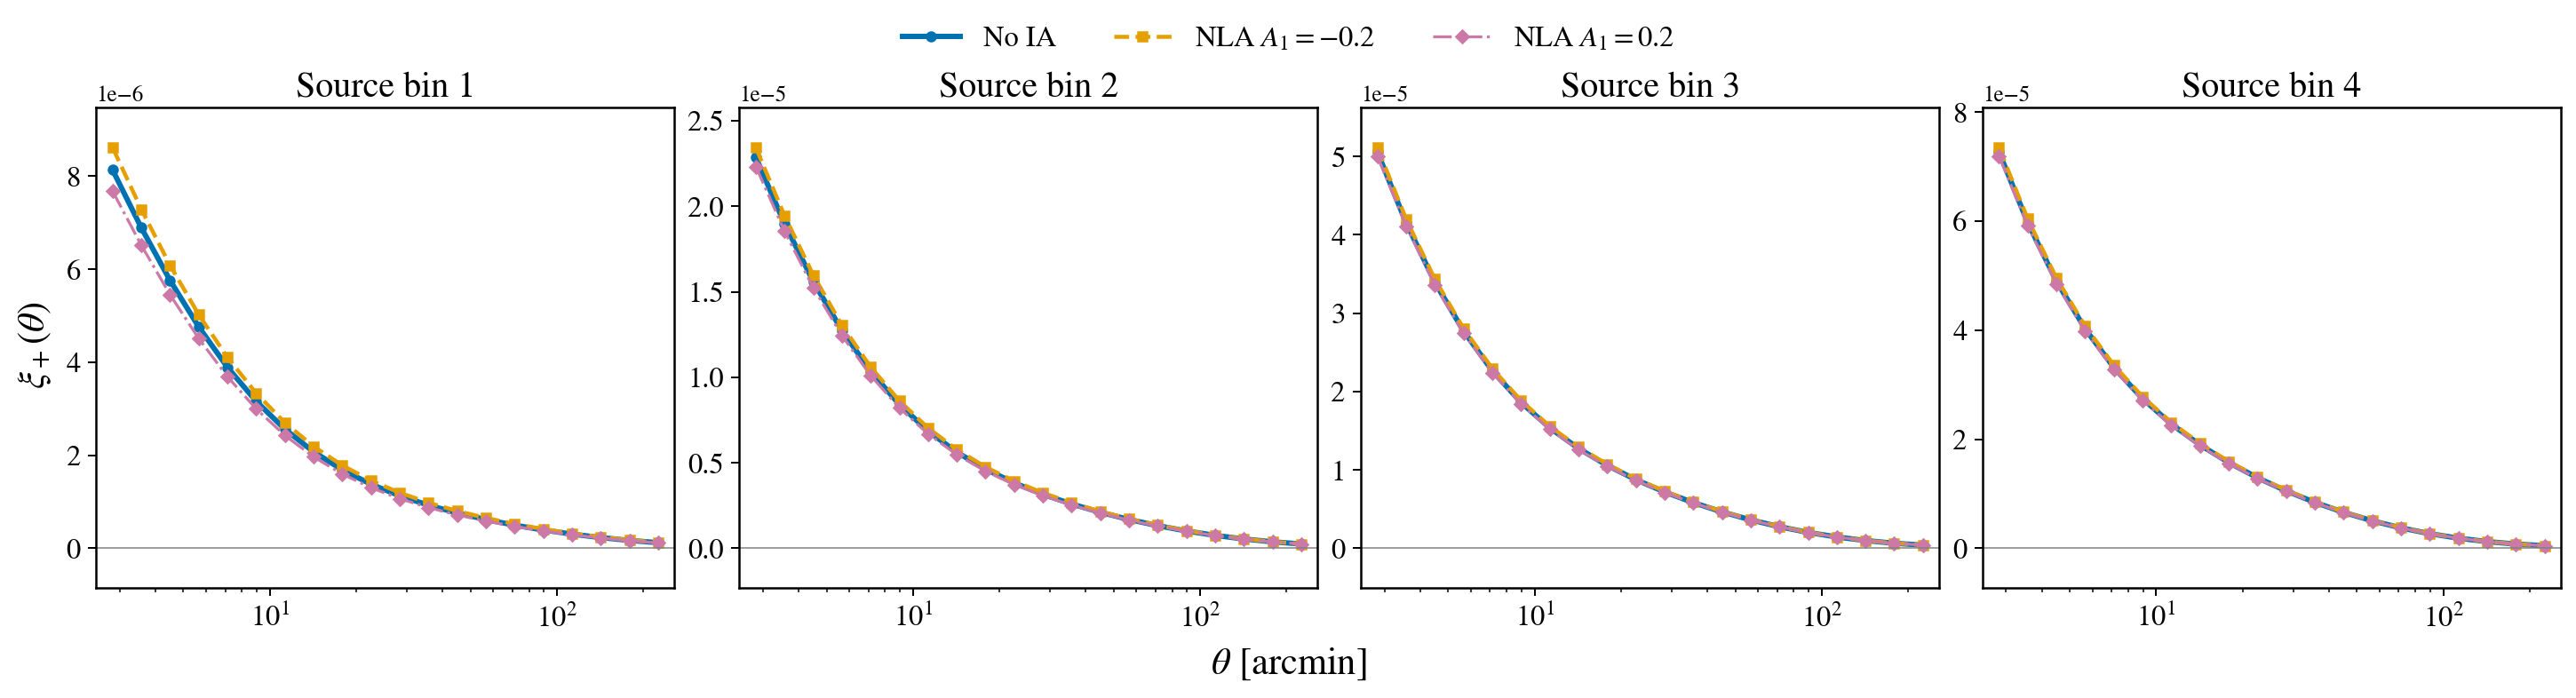

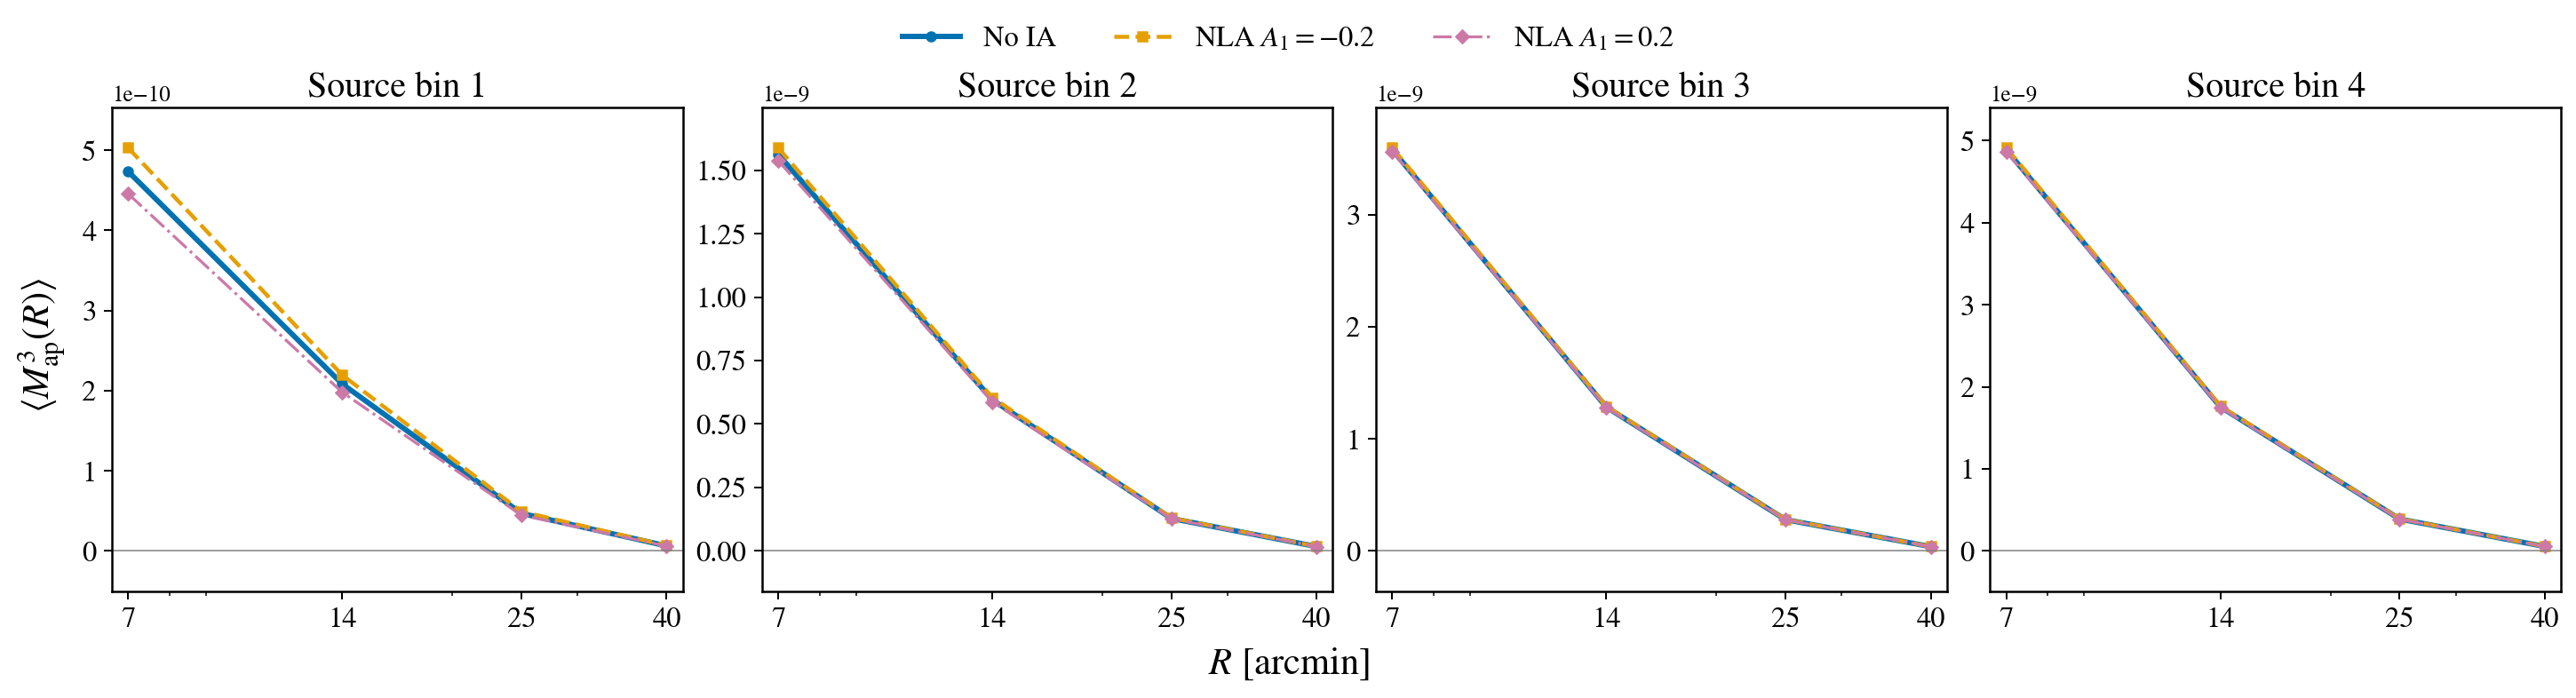

IA model: TATT


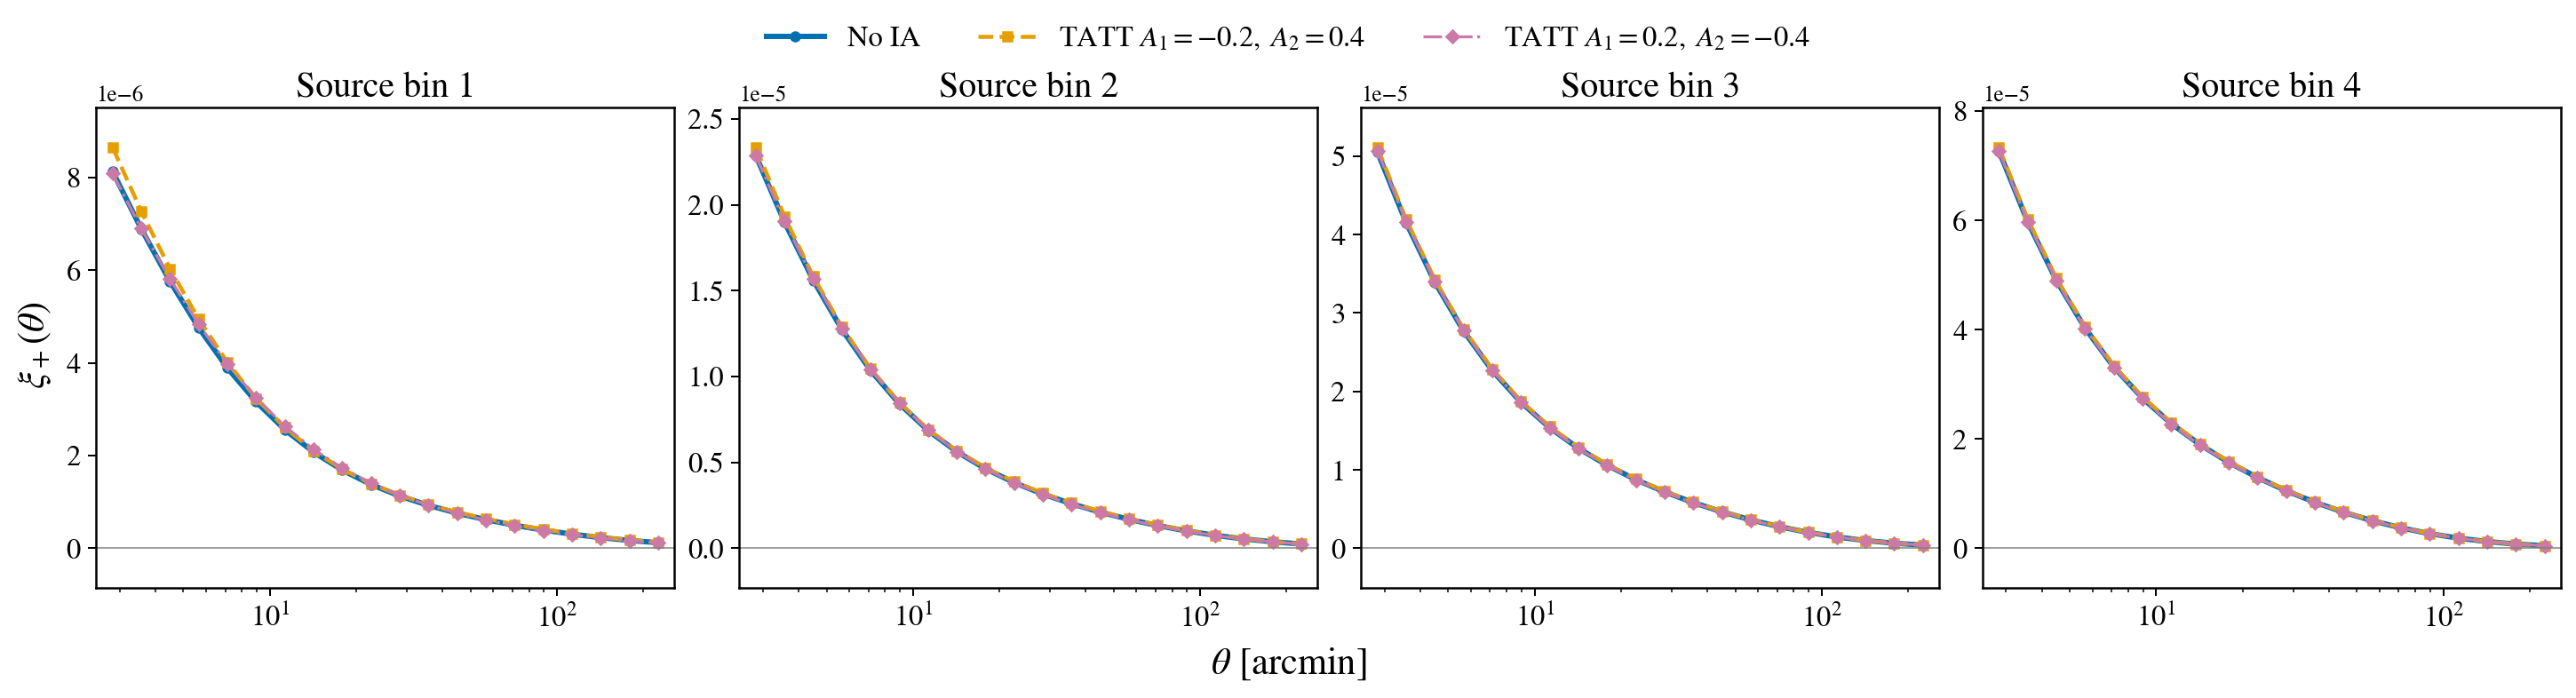

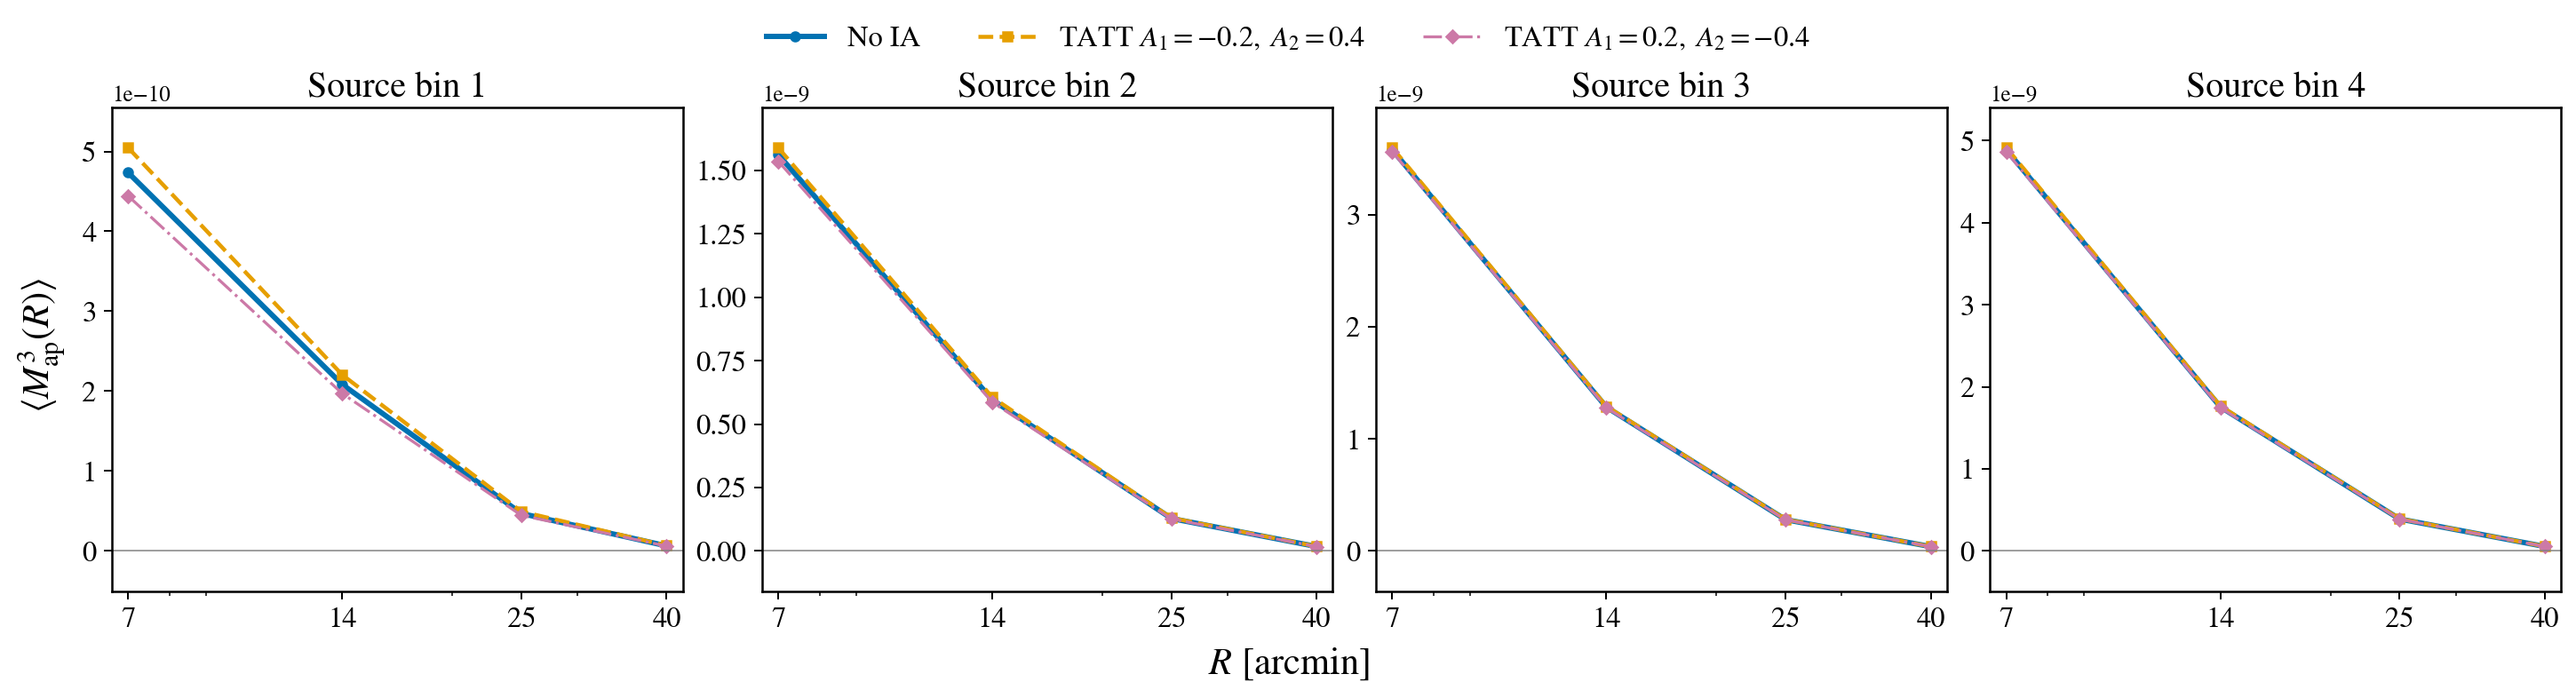

In [5]:
sign_plan = nw.ia_figure9_workflows(workflow=workflows["tatt"])
sign_results = {}
for name, case in sign_plan["workflows"].items():
    print(name, "IA parameters:", sign_plan["ia_parameters"][name])
    result, declaration = case.ensure_result(command="evaluate")
    sign_results[name] = result
for model, group in sign_plan["groups"].items():
    print("IA model:", model.upper())
    curves = [sign_results[key] for key in group["keys"]]
    for kind in ("xip", "map3"):
        response_figure, response_axes = nw.plot_mean_responses(
            results=curves, labels=group["labels"], kind=kind,
        )
        plt.show()

Residual panels show $100[X-X_\mathrm{no\,IA}]/\max|X_\mathrm{no\,IA}|$, with
one scale for the whole angular curve in each bin, so the display stays
defined at a zero crossing; it is not a pointwise percentage. The panels share
the paper's no-IA reference while keeping this different display
normalization. Similar curves in a few panels do not establish a degeneracy of
the full data vector, which includes every bin, angle and correlation.

Residuals relative to no IA: NLA


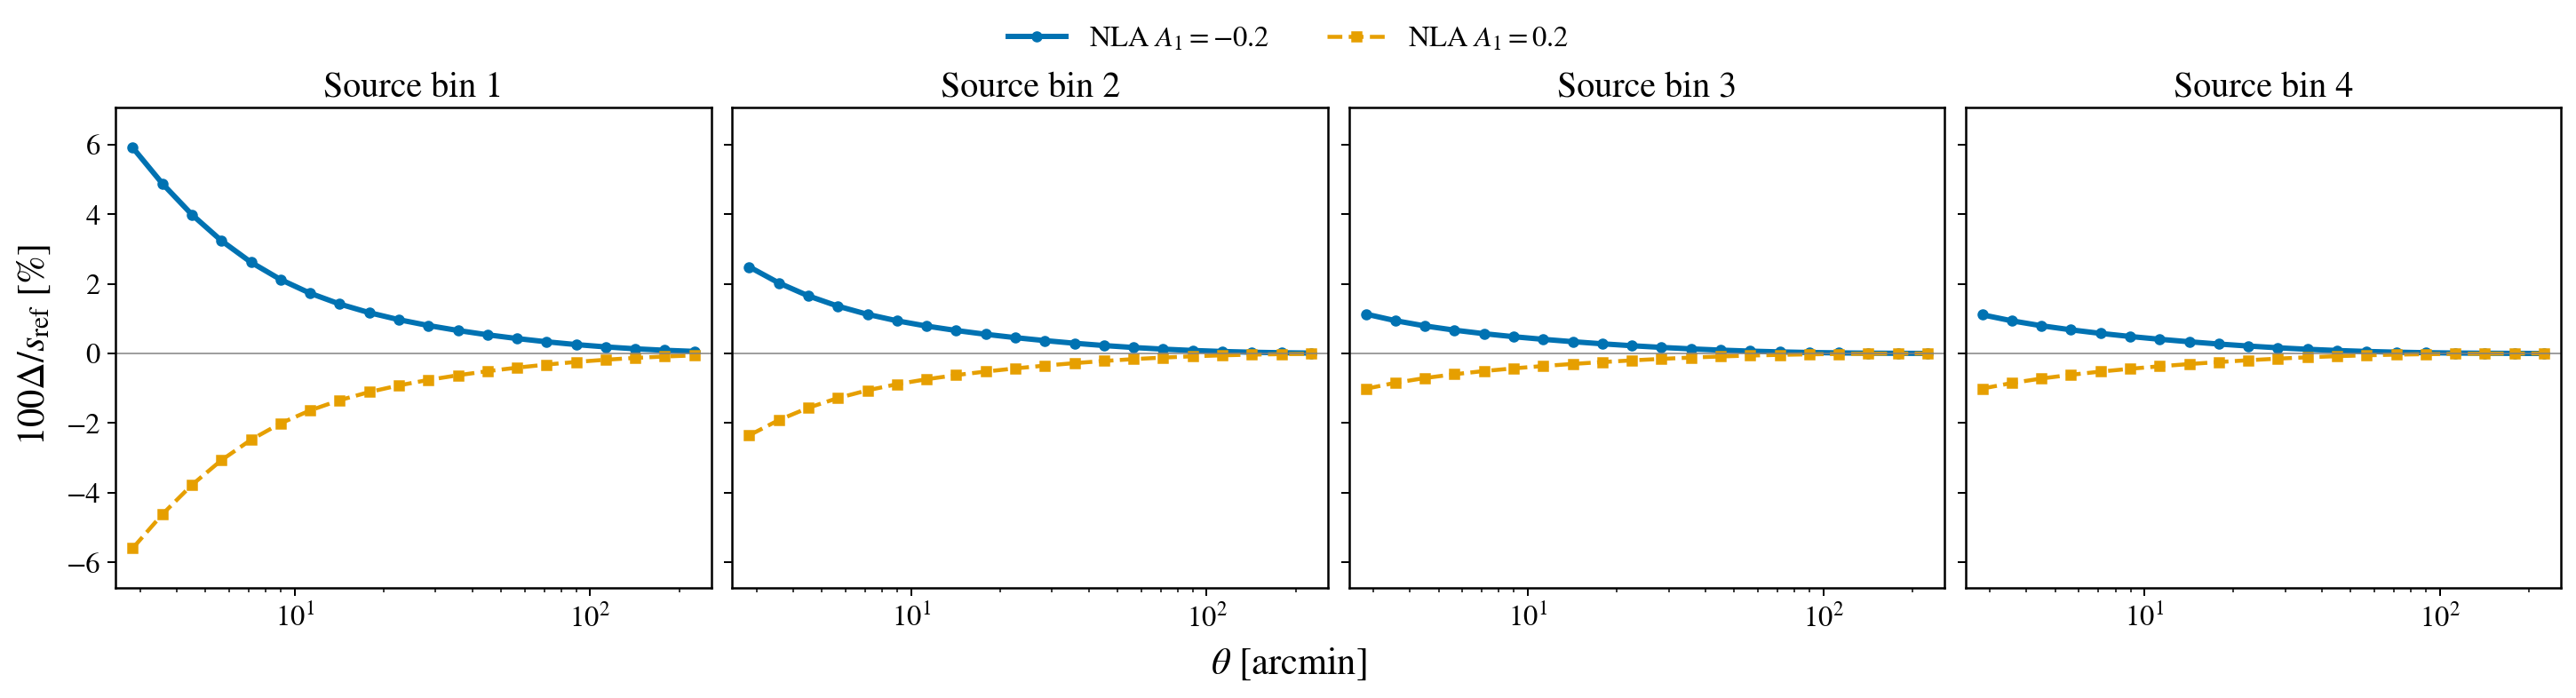

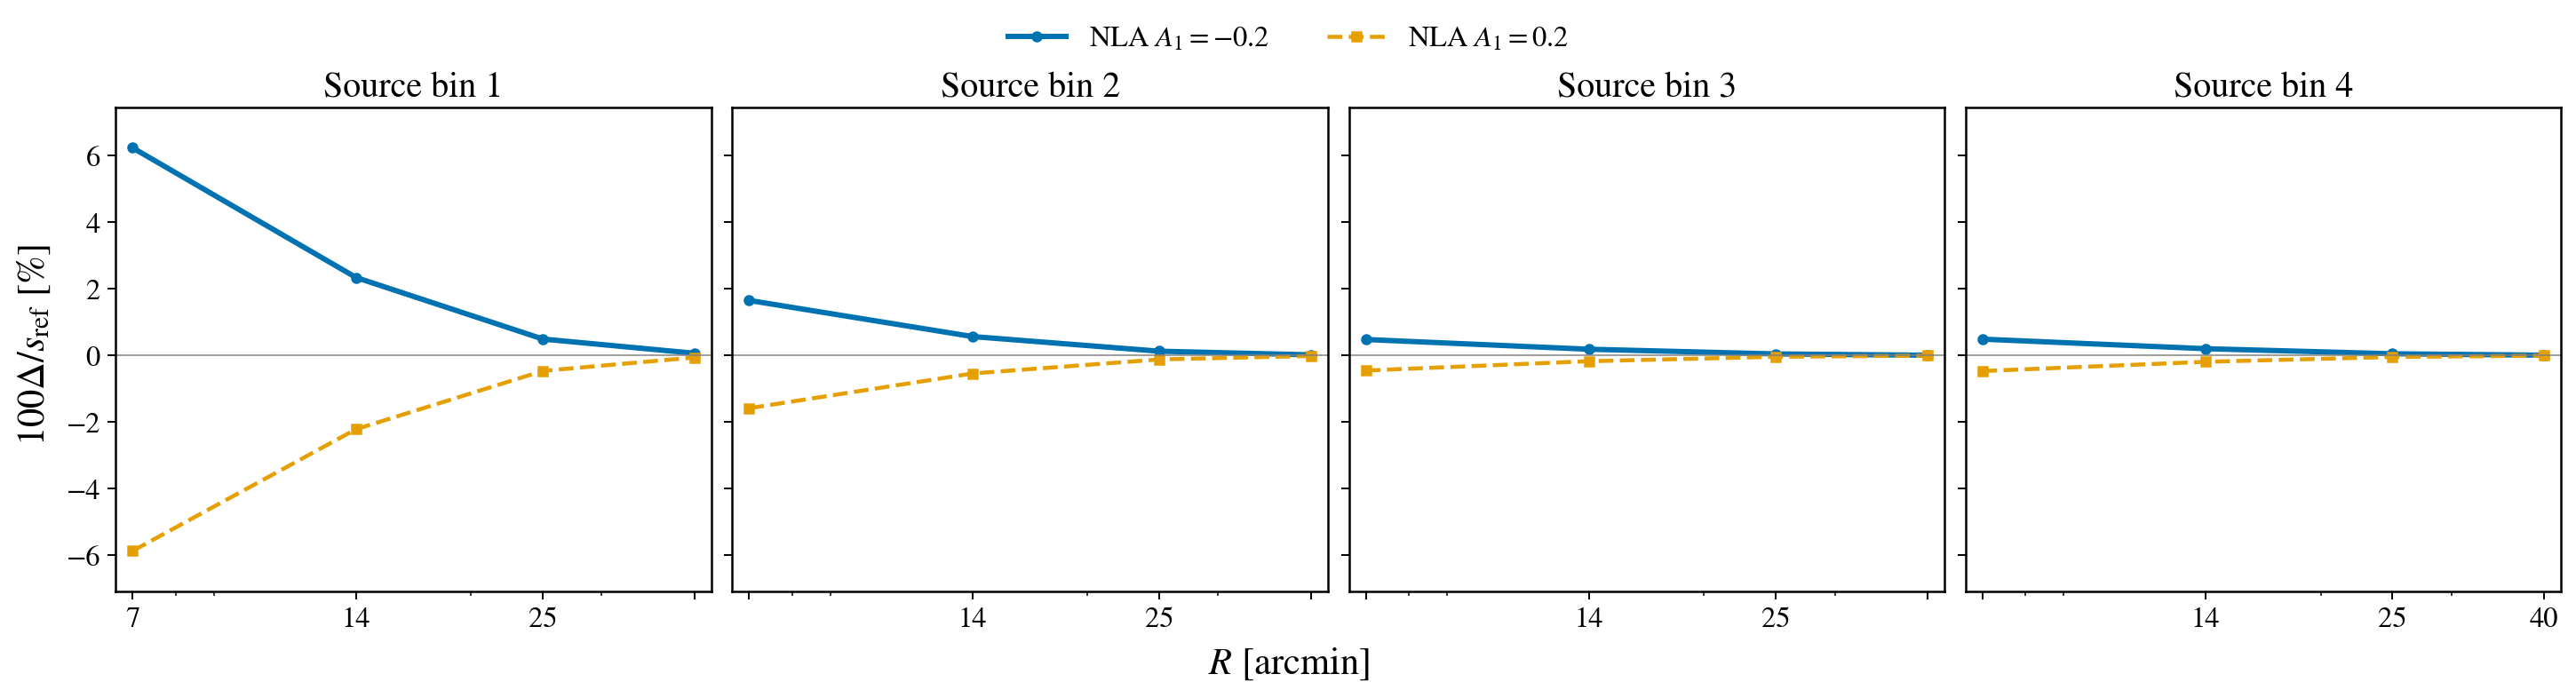

Residuals relative to no IA: TATT


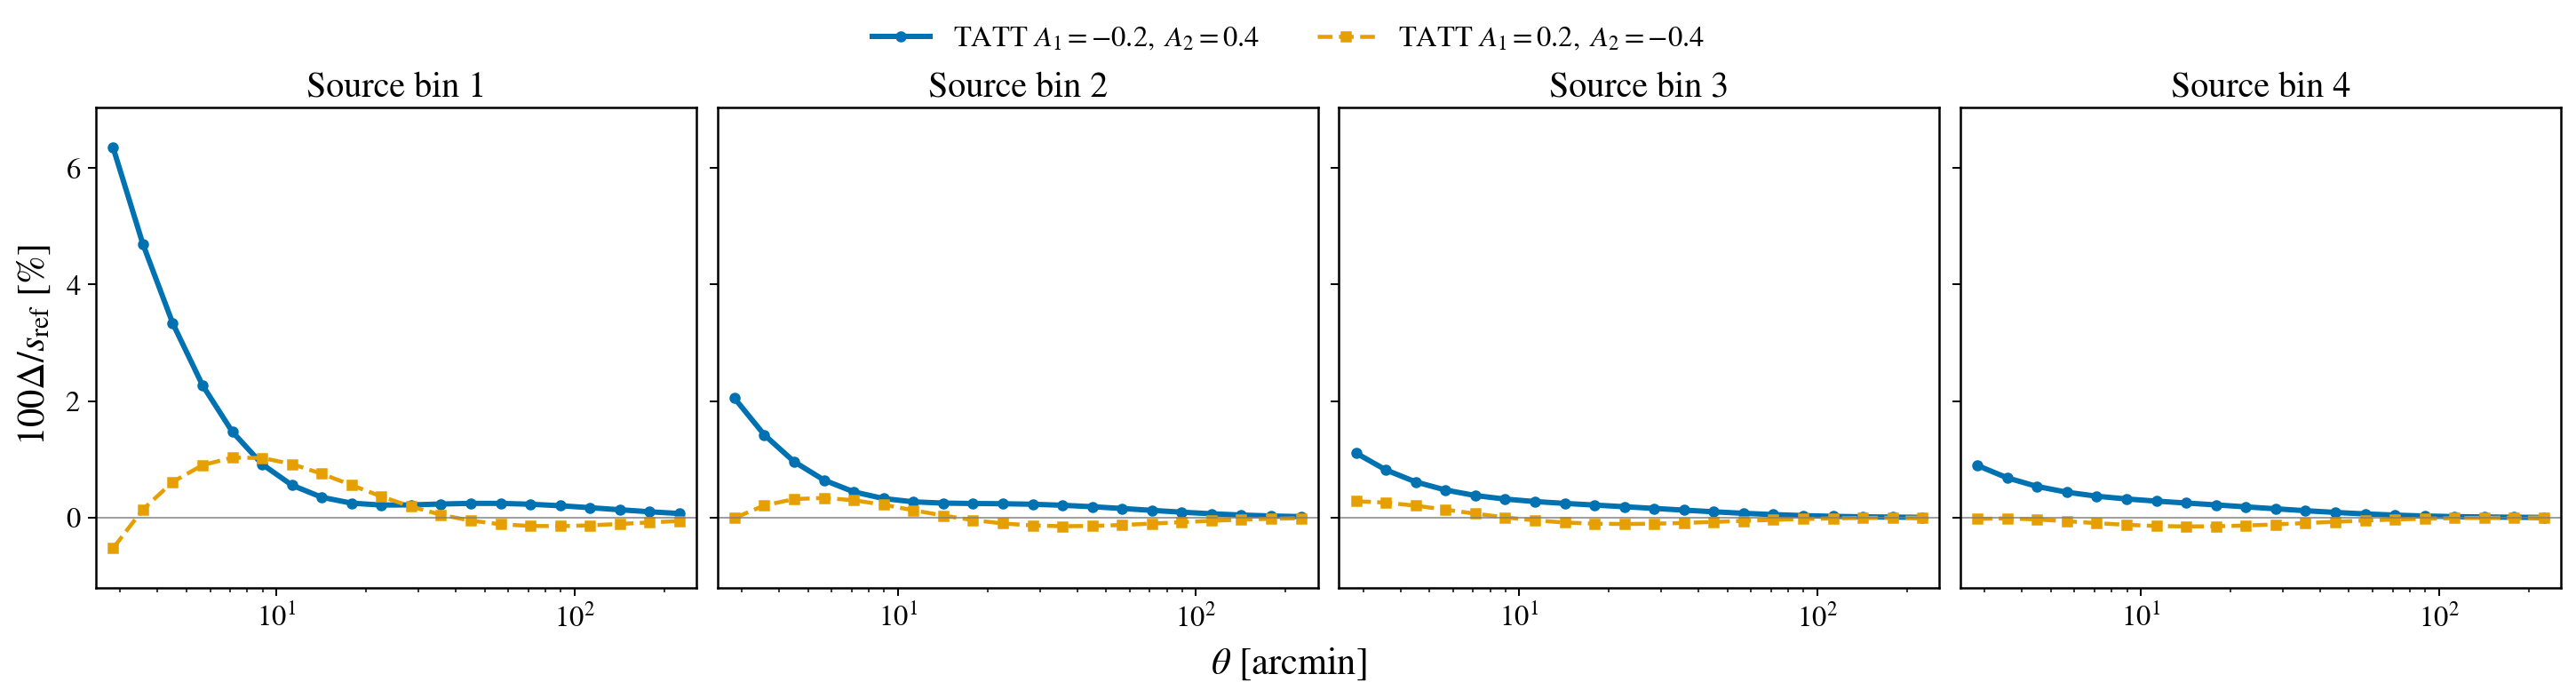

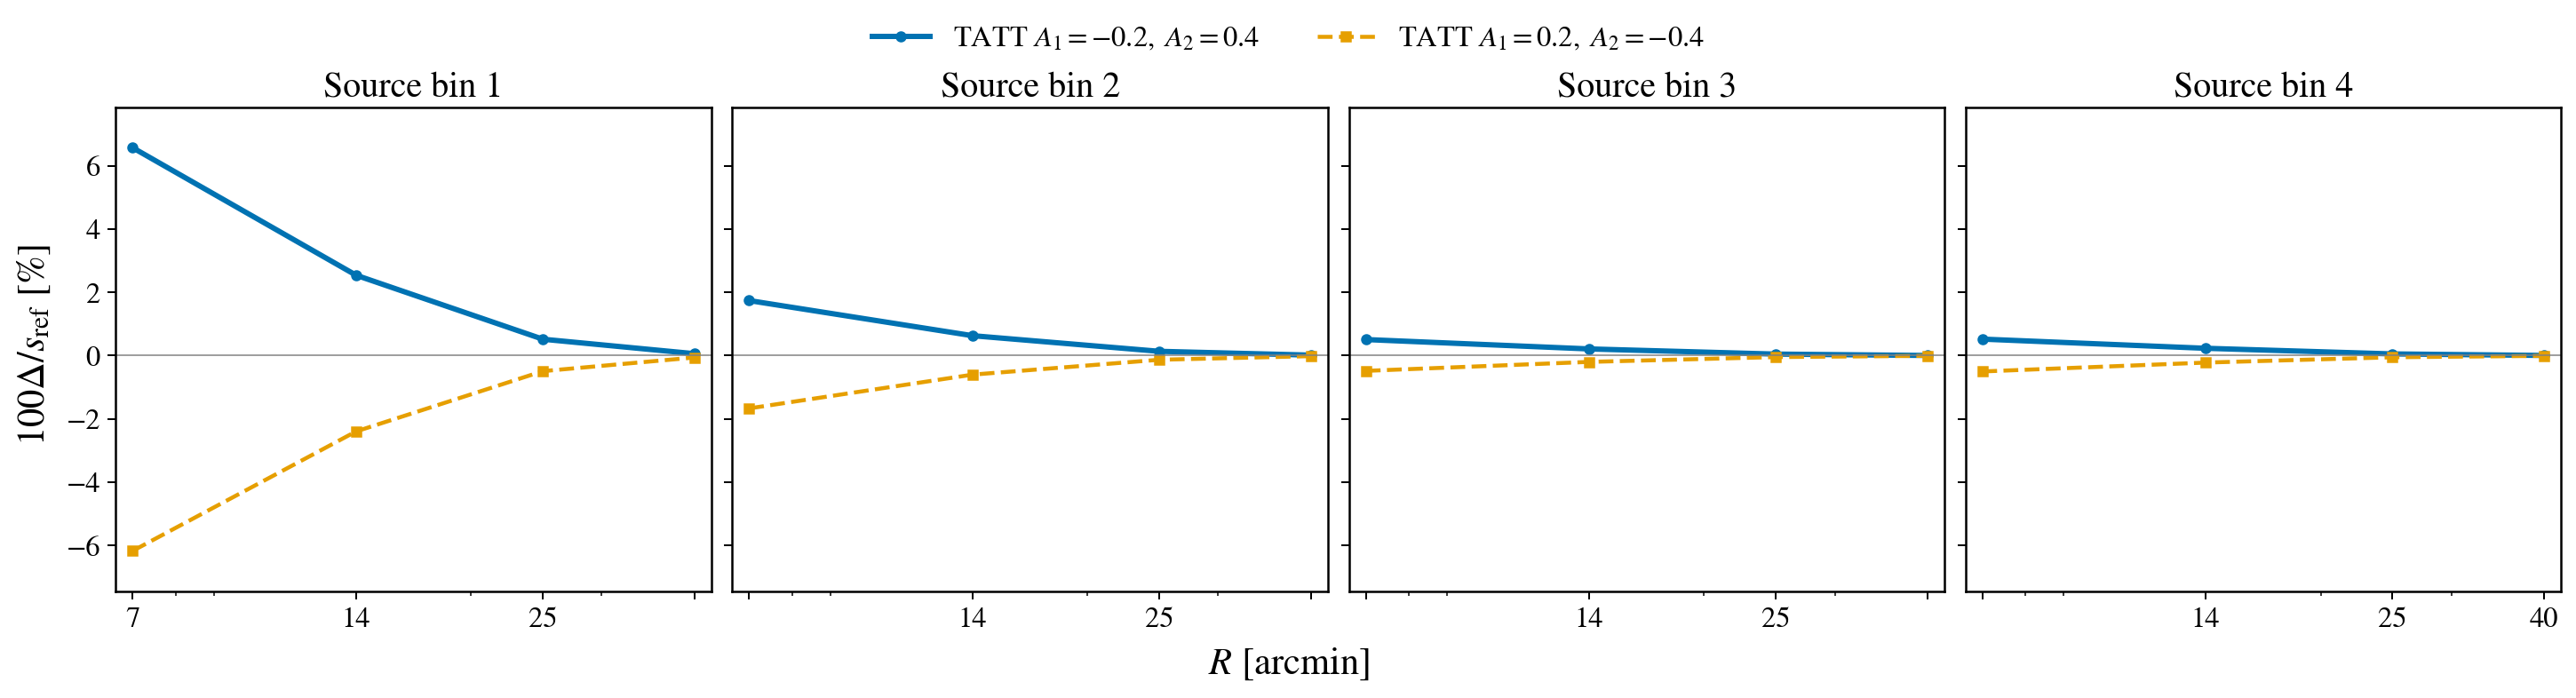

In [6]:
for model, group in sign_plan["groups"].items():
    print("Residuals relative to no IA:", model.upper())
    curves = [sign_results[key] for key in group["keys"]]
    for kind in ("xip", "map3"):
        response_figure, response_axes = nw.plot_mean_responses(
            results=curves, labels=group["labels"], kind=kind, residual=True,
        )
        plt.show()

## 4. What the joint Fisher matrix measures

For mean $\mu(\boldsymbol p)$ and fixed covariance $C$, let
$D_{a\alpha}=\partial\mu_a/\partial p_\alpha$. A local Gaussian forecast is

$$F_{\alpha\beta}=D_{a\alpha}(C^{-1})_{ab}D_{b\beta}
+F^\mathrm{prior}_{\alpha\beta},$$

with repeated data indices summed. Diagonal entries of $F^{-1}$ are squared
**marginalized** errors, where every other varied parameter can move; in
contrast, $1/\sqrt{F_{\alpha\alpha}}$ holds those parameters fixed. An
unresolved matrix produces a rank diagnostic, never a pseudoinverse error bar.

Partition the data into two- and three-point rows, $(d_2,d_3)$. Removing the
part of the three-point fluctuation that $d_2$ predicts gives

$$S=C_{33}-C_{32}C_{22}^{-1}C_{23},\qquad
E=D_3-C_{32}C_{22}^{-1}D_2.$$

The likelihood information is then

$$F_\mathrm{joint}=F_2+F_{3|2},\qquad F_{3|2}=E^{\mathsf T}S^{-1}E.$$

The added term is conditional on the two-point measurement, not an
independently computed three-point Fisher matrix. Priors enter once per
experiment, and the saved arrays keep $S$, $E$ and all Fisher pieces.

Both models use the same calibration and photo-z prior widths. NLA and TATT
vary different IA spaces, so their cosmological contours describe different
marginalizations, and a finite-difference bound is not a Gaussian prior.

### A finite comparison before differentiating

For the two opposite-sign choices in each model, replace the derivative
columns above by their finite mean difference $\Delta\mu$. Then
$r_{3|2}=\Delta\mu_3-C_{32}C_{22}^{-1}\Delta\mu_2$ and
$\Delta\chi^2_\mathrm{joint}=\Delta\chi^2_2+r_{3|2}^{\mathsf T}S^{-1}r_{3|2}$.
The printed identity checks this decomposition with all 480 saved rows. It
asks how far apart the two fixed predictions sit in the stated covariance; no
nuisance parameter is fitted, and the number is neither a detection
significance nor a marginalized constraint.

The covariance enters in its published paired-file convention. The public
packing scripts examined in the estimator record do not reconstruct its
realization-level sign preparation, and changing a Map3 sign would require
changing both its mean and the covariance cross block; nothing here warrants
changing either input.

In [7]:
for model, group in sign_plan["groups"].items():
    separation = nw.finite_sign_pair_separation(
        first=sign_results[group["keys"][1]],
        second=sign_results[group["keys"][2]],
        covariance=covariance,
    )
    print(model.upper(), "fixed-model squared distances:")
    for name in ("chi2_two_point", "chi2_conditional_three_point", "chi2_joint"):
        print(name, separation[name])
    print("Decomposition relative error:", separation["identity_relative_error"])

NLA fixed-model squared distances:
chi2_two_point 7.920110956087057
chi2_conditional_three_point 7.404752246279902
chi2_joint 15.324863202366952
Decomposition relative error: 4.636535585194361e-16
TATT fixed-model squared distances:
chi2_two_point 5.185118419629394
chi2_conditional_three_point 2.443853636707884
chi2_joint 7.628972056337279
Decomposition relative error: 2.3284353727900417e-16


## 5. Read or run the demonstration forecasts

Each YAML lists absolute parameter displacements $h$. The driver computes
five-point derivatives at $h$ and $h/2$, keeps both, and holds one covariance
fixed across every displacement; it varies $w_0$ and $w_a$ without Gaussian
priors. The printed mean count is a work count, not a runtime estimate.

These cells run the forecast when its saved result is absent. The
configuration hash includes comments, so an edited YAML needs a matching
result, and a hash match does not establish numerical convergence: inspect the
rank and step checks before interpreting the error bars, then use the accuracy
notebook to test quadrature and interpolation separately. For each parameter,
the printed step percentage is $100\|D_h-D_{h/2}\|_C/\|D_{h/2}\|_C$, with
$\|v\|_C^2=v^{\mathsf T}C^{-1}v$; the complete covariance keeps the much
smaller raw aperture amplitudes from disappearing behind the two-point
amplitudes. Step agreement alone does not establish grid convergence.

In [8]:
forecasts = {}
declarations = {}
for model in ("nla", "tatt"):
    inspection = workflows[model].inspect(command="fisher")
    print(model.upper(), inspection["description"])
    print("Parameters:", inspection["varied_parameters"])
    print("Mean evaluations:", inspection["distinct_mean_evaluations"])
    print("Gaussian priors:", inspection["gaussian_prior_sigmas"])
    forecasts[model], declarations[model] = workflows[model].ensure_result(
        command="fisher",
    )
    summary = nw.fisher_summary(
        result=forecasts[model], metadata=declarations[model],
    )
    print("Rank:", summary["rank_status"])
    print("Conditional identity relative error:",
          summary["information_identity_relative_error"])
    for name, change in zip(
        summary["names"], summary["derivative_covariance_relative_change"],
    ):
        print(f"{name}: covariance-weighted h/h2 change = {100.0 * change:.6g}%")

NLA Demonstration DES Y3 NLA joint xi± + Map3 Fisher forecast with w0 and wa, all 480 public rows and recorded source clipping.
Parameters: ['omega_m', 'sigma8', 'omega_b', 'h', 'ns', 'a1', 'eta1', 'm1', 'm2', 'm3', 'm4', 'dz1', 'dz2', 'dz3', 'dz4', 'w0', 'wa']
Mean evaluations: 103
Gaussian priors: {'m1': 0.0091, 'm2': 0.0078, 'm3': 0.0076, 'm4': 0.0076, 'dz1': 0.018, 'dz2': 0.015, 'dz3': 0.011, 'dz4': 0.017}
Reading saved fisher: /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/runs/y3_nla_measured_edge_demo_fisher.npz
Rank: {'joint': 'resolved', 'two_point': 'resolved'}
Conditional identity relative error: 5.669348596720082e-16
omega_m: covariance-weighted h/h2 change = 0.425681%
sigma8: covariance-weighted h/h2 change = 0.00539264%
omega_b: covariance-weighted h/h2 change = 0.138755%
h: covariance-weighted h/h2 change = 1.75076%
ns: covariance-weighted h/h2 change = 0.0652794%
a1: covariance-weighted h/h2 change = 1.04152e-09%
eta1: covarianc

### Derivative shapes: which parameter can imitate another?

A derivative describes the change of every measurement for a small change of
one parameter, with the others held fixed. Two proportional derivatives
produce the same pattern across the data vector, so a fit can exchange those
two parameter changes without changing its prediction; opposite signs do not
remove the ambiguity, because one parameter can move in the opposite
direction. The FoG and counterterm note
(`projects/lssty1xdesi/notes/fog_parameter_degeneracy_study/fog_parameter_degeneracy_study.tex`;
FoG, Fingers of God, is the smearing of redshift-space clustering by random
galaxy velocities) shows the same mechanism with the velocity-dispersion and
counterterm responses, and this section uses its normalization and
fitted-residual construction.

Let $D_{ip}=\partial\mu_i/\partial p$ and $\sigma_i=\sqrt{C_{ii}}$. The upper
panels show

$$t_{ip}=\frac{\Delta_p D_{ip}}{\sigma_i}.$$

A value of one means that the local linear response over the stated parameter
interval equals one error bar of that individual data row. The derivative
belongs to the saved fiducial and does not assert that a finite change of that
size stays linear. The display intervals are $\Delta A_1=1$, $\Delta A_2=1$
and $\Delta\sigma_8=0.1$: display choices, not priors, fitted uncertainties or
numerical derivative steps. The display divides no curve by its own maximum,
the mean signal, or the fiducial parameter value, so zero crossings stay
visible.

The diagonal-error normalization preserves the angle and source identity of
every plotted measurement; it does not make correlated measurements
independent. In observable units define $a=\Delta_p D_p$ and
$b=\Delta_q D_q$. The coefficient

$$c=\frac{b^{\mathsf T}C^{-1}a}{b^{\mathsf T}C^{-1}b}$$

minimizes the remaining response $r=a-cb$. The code fits it once with all 400
xi rows and once with all 480 joint rows and the cross-covariance, and the
lower panels show $r_i/\sigma_i$. In the Map3 panel the xi-fit coefficient
carries over unchanged, asking whether a parameter change that imitates xi
also imitates the third-order signal; the joint-fit coefficient instead
balances the mismatch across both measurements.

Each figure displays one source auto-bin while both fits include every auto-
and cross-bin row. The first and fourth source bins illustrate two redshift
ranges, and the coefficients are not tuned to favor either panel. All other
parameters stay fixed for this diagnostic; the marginalized IA error plot
below asks the different question in which they vary.

NLA A1 response fitted by sigma8
two_point coefficient: -0.26258282603843236
  Signed derivative overlap: -0.7471905242687393
  Reproduced information [%]: 55.82936795569935
  Residual joint squared norm: 38.45296977427153
  xi plus conditional Map3: 23.321252973706677 15.131716800564838
joint coefficient: -0.24776023113048506
  Signed derivative overlap: -0.7923534080860225
  Reproduced information [%]: 62.78239233055349
  Residual joint squared norm: 38.22219395384741
  xi plus conditional Map3: 23.41518135128126 14.807012602566143
NLA source bin 1


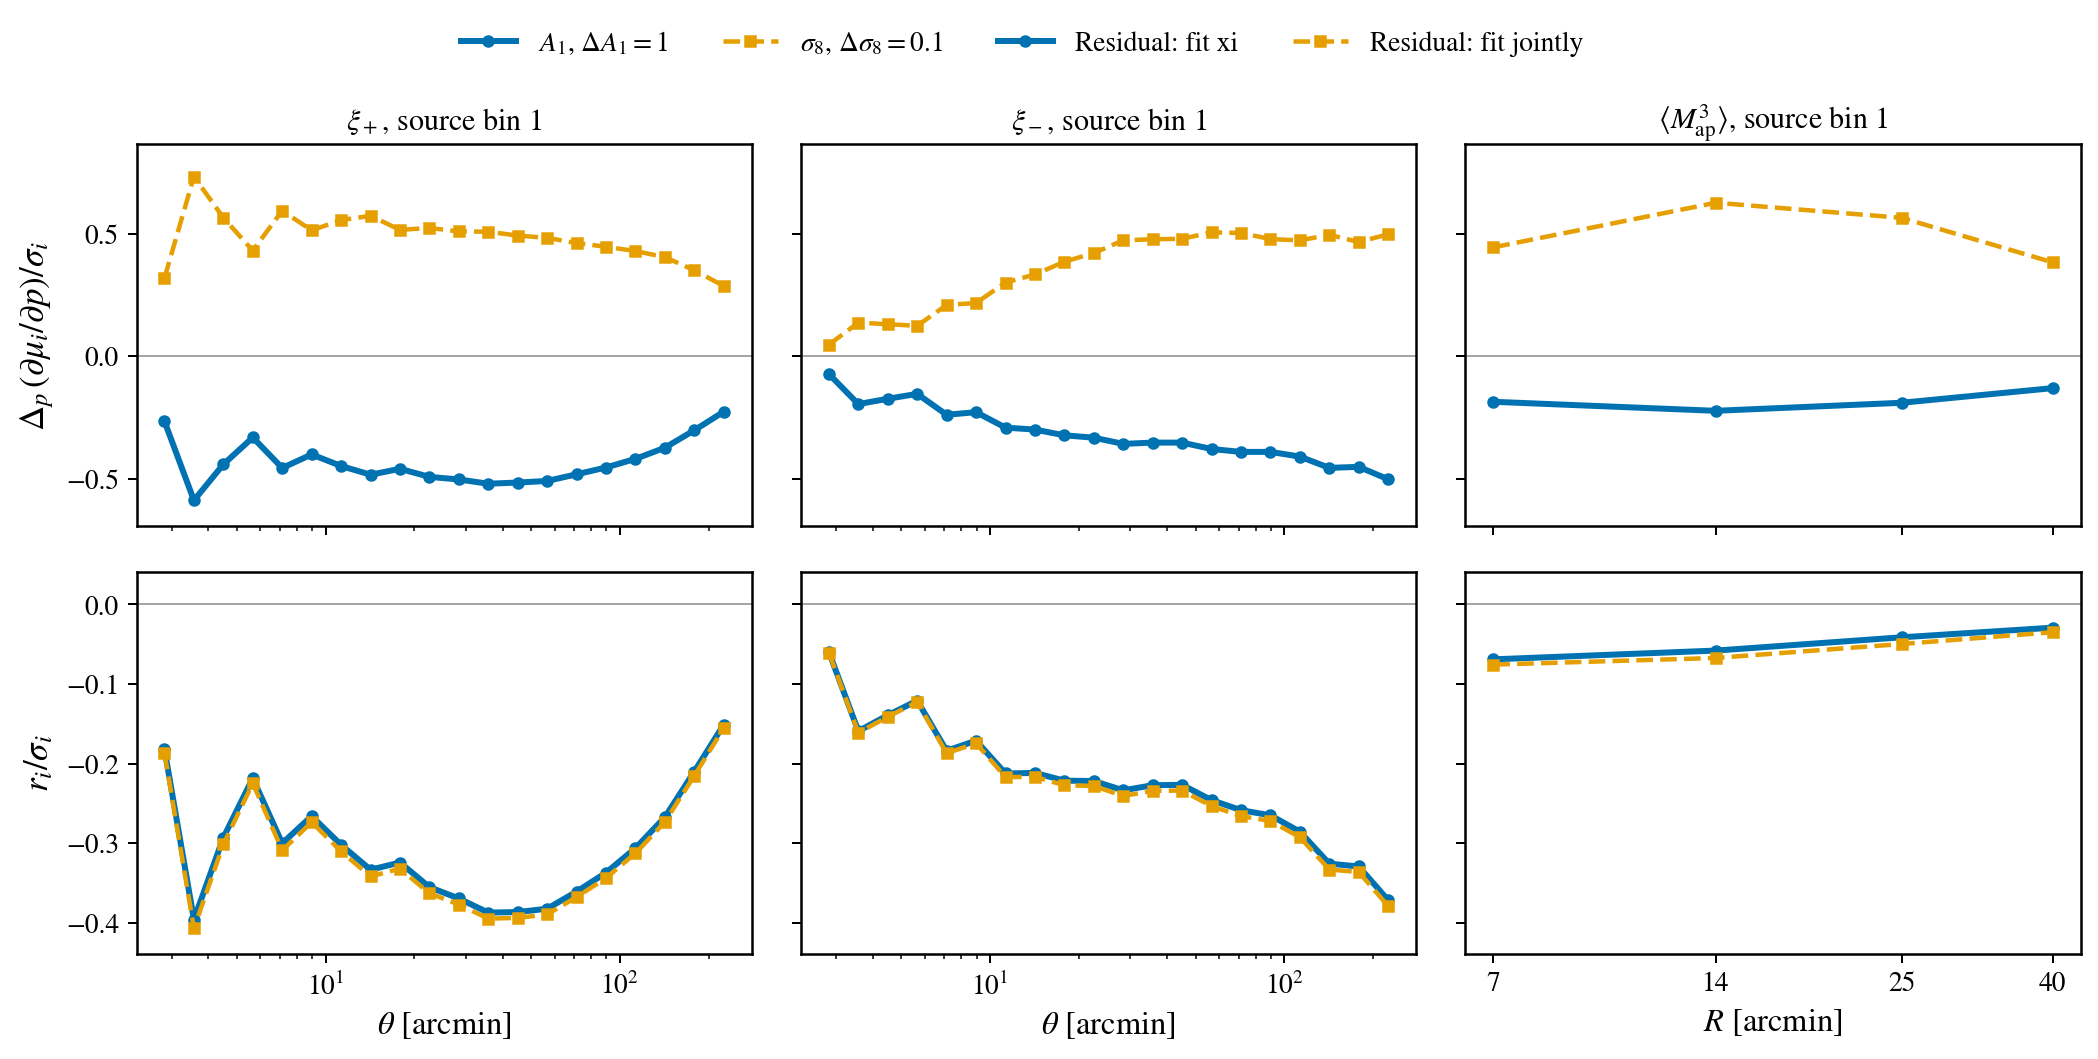

NLA source bin 4


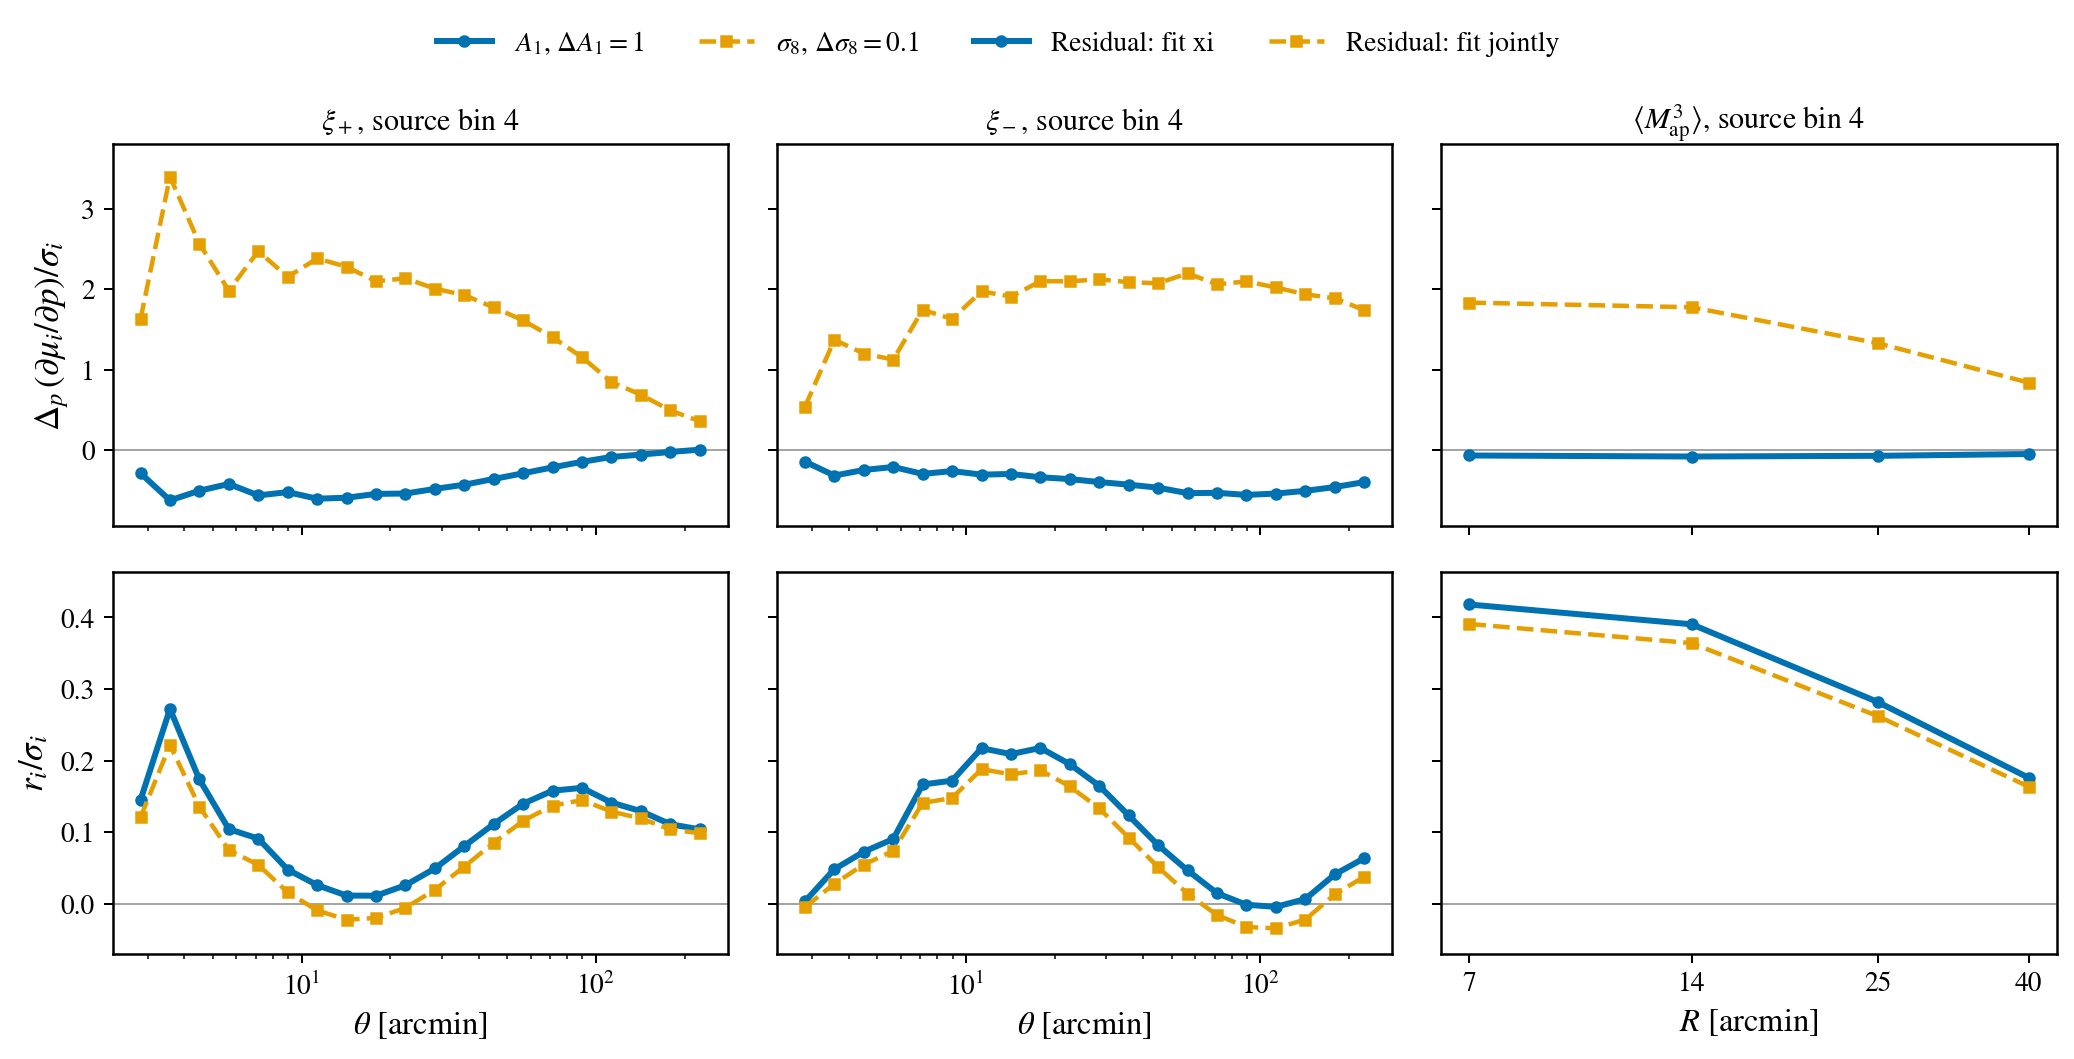

TATT A1 response fitted by a2
two_point coefficient: 2.095109129909387
  Signed derivative overlap: 0.7449832490873977
  Reproduced information [%]: 55.50000414208156
  Residual joint squared norm: 94.133991642502
  xi plus conditional Map3: 68.4496233336553 25.684368308846743
joint coefficient: 2.292353013218779
  Signed derivative overlap: 0.8069097488309476
  Reproduced information [%]: 65.11033427584229
  Residual joint squared norm: 92.8511166483177
  xi plus conditional Map3: 69.20627831816611 23.644838330151615
TATT source bin 1


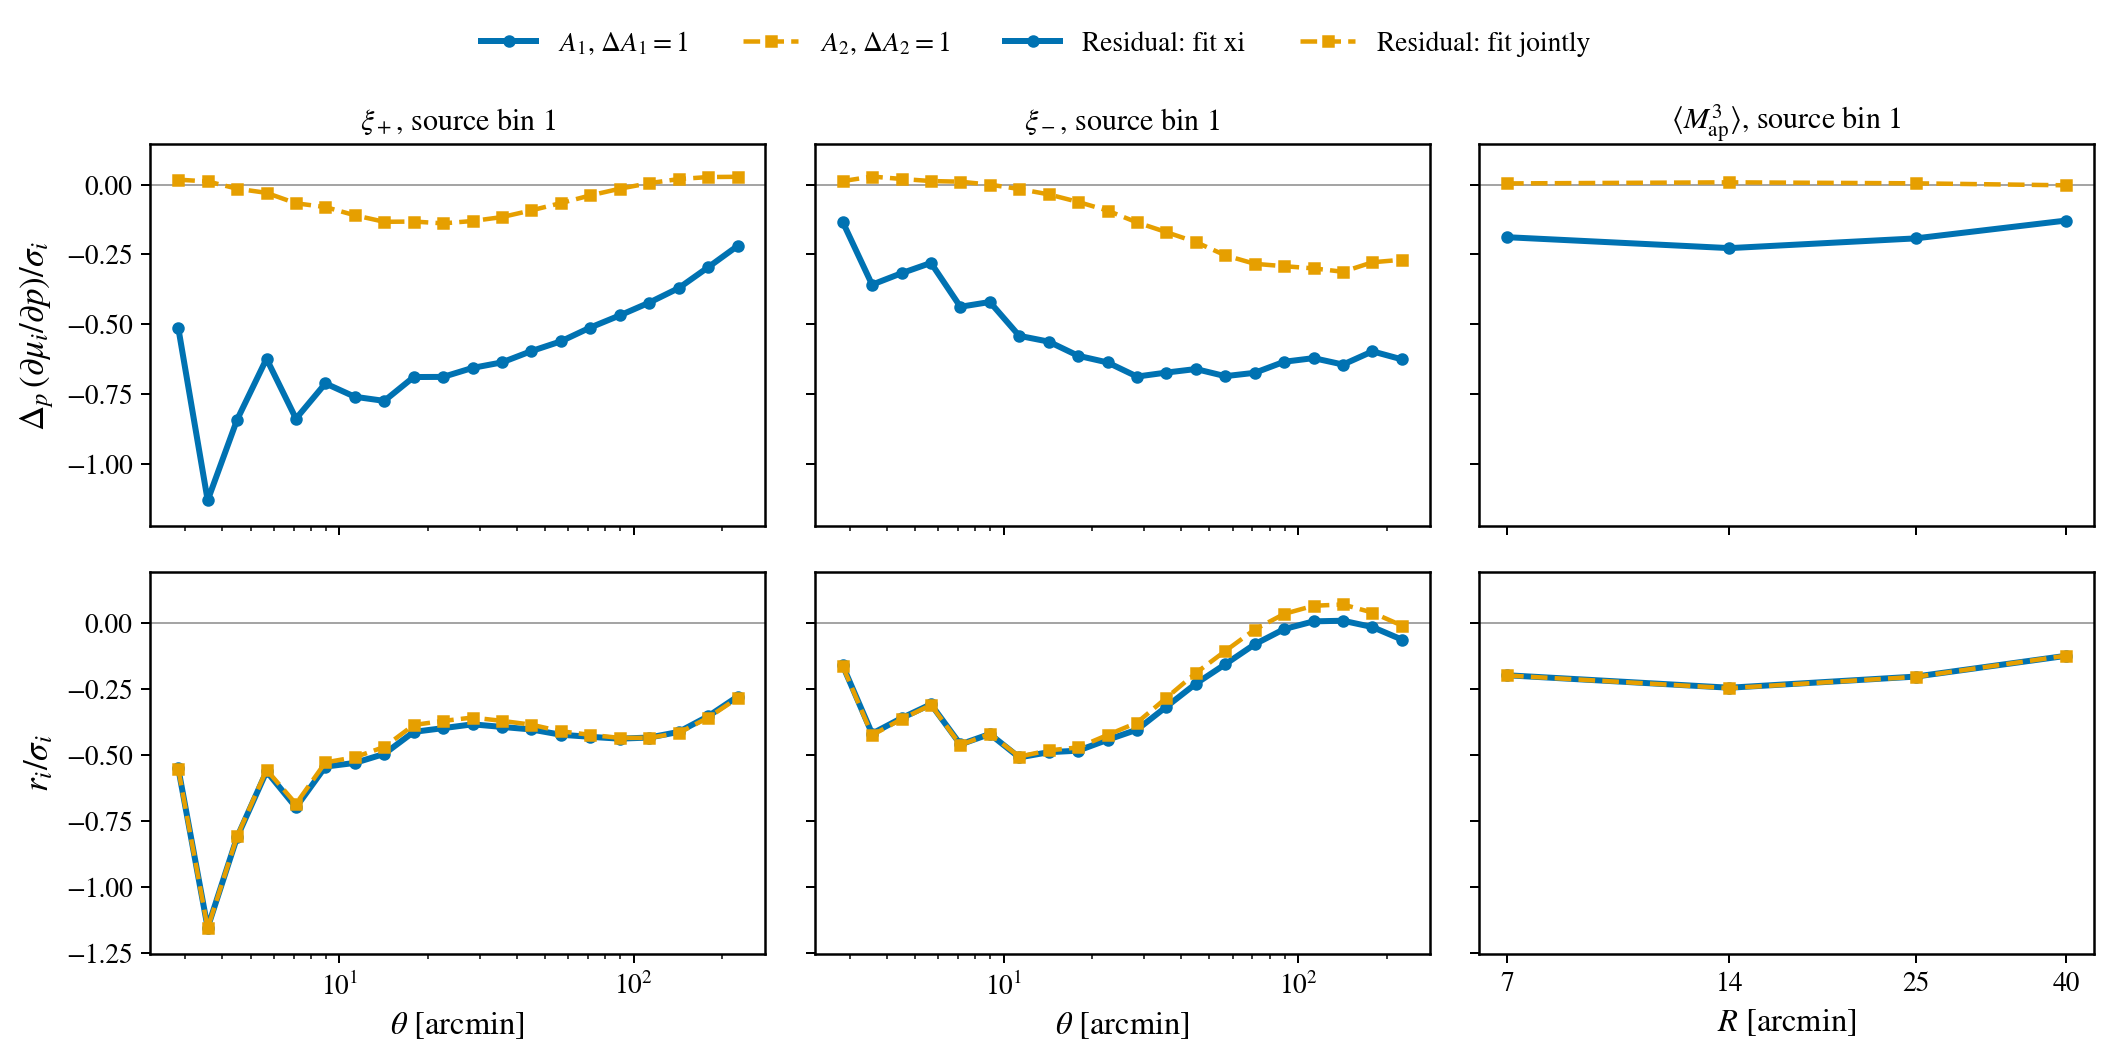

TATT source bin 4


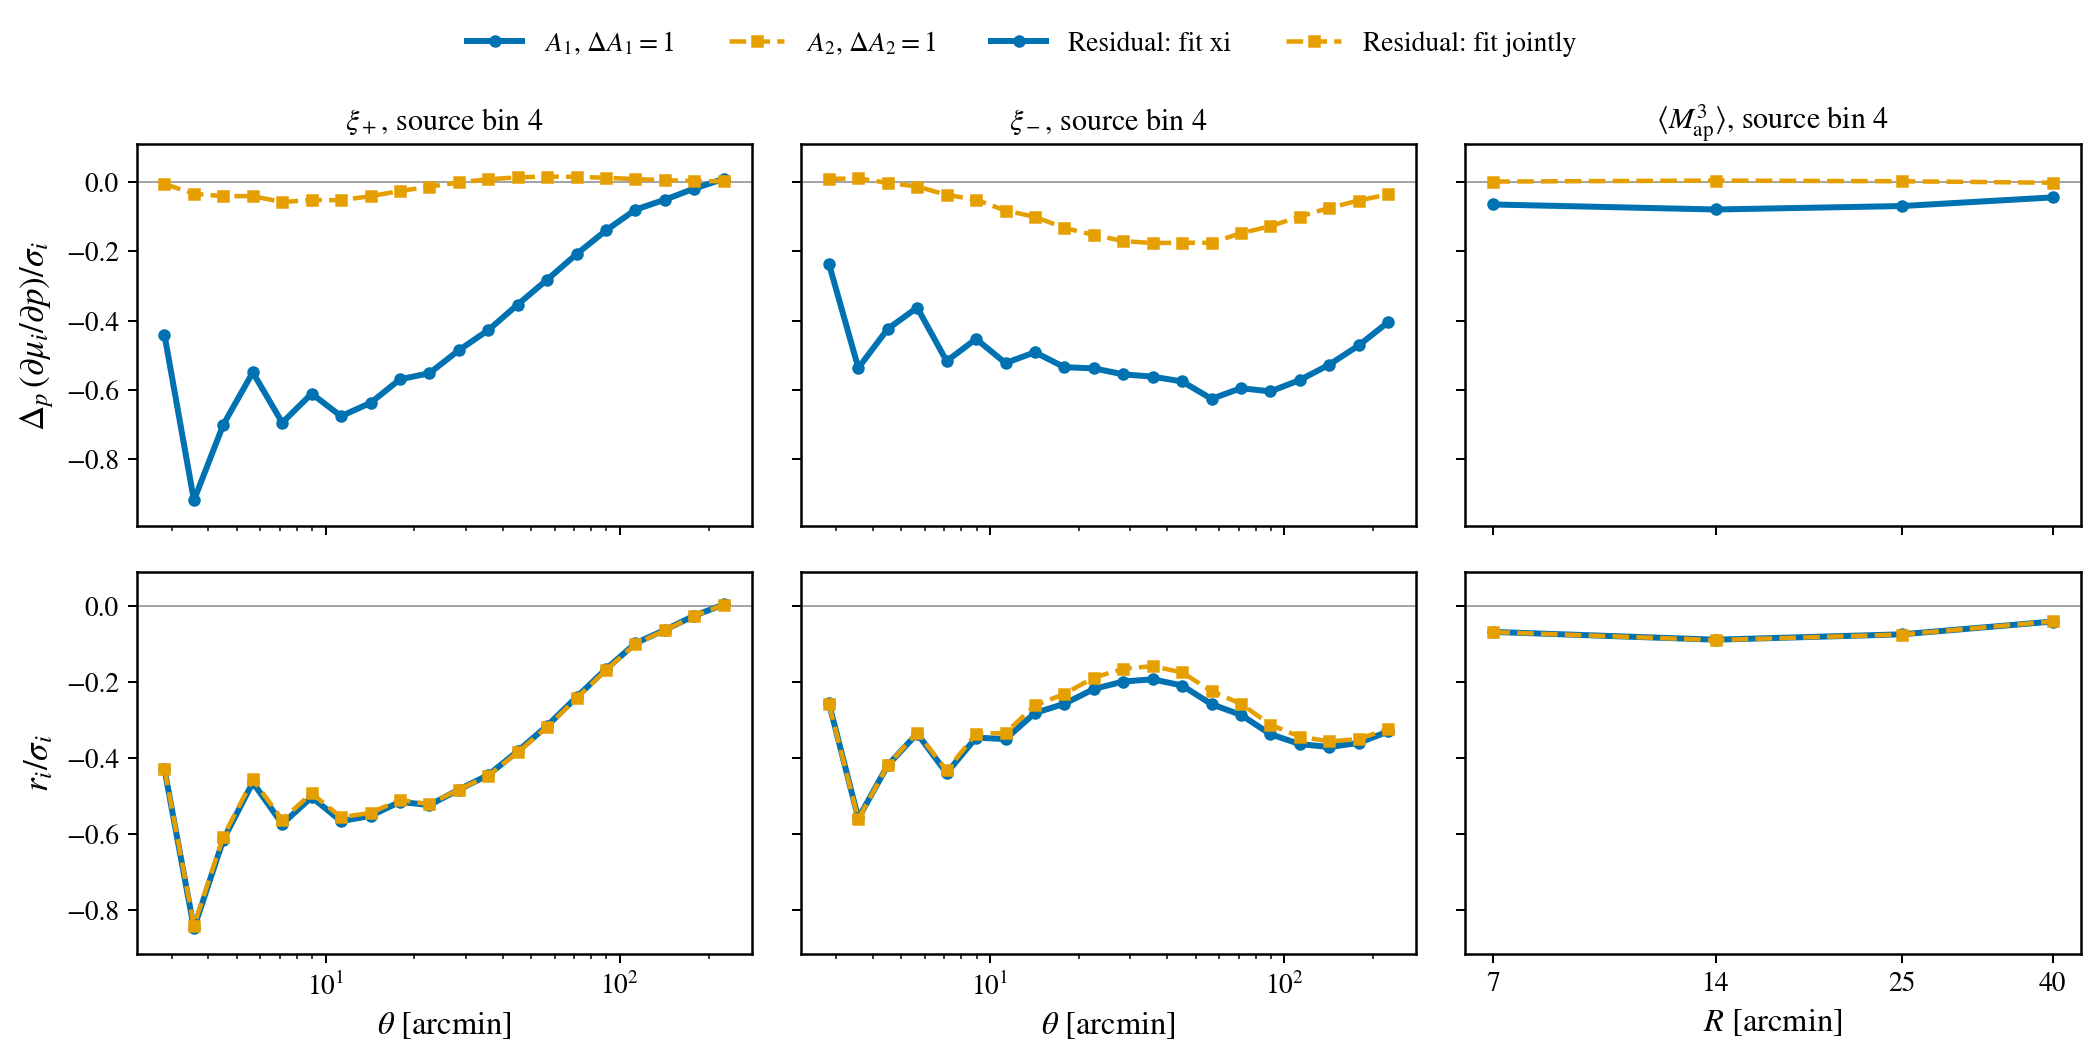

In [9]:
import cosmolike_des_3pcf_template_wrappers as tw

template_comparisons = {}
for model, mimic, mimic_scale, mimic_label in (
    ("nla", "sigma8", 0.1, r"$\sigma_8$, $\Delta\sigma_8=0.1$"),
    ("tatt", "a2", 1.0, r"$A_2$, $\Delta A_2=1$"),
):
    comparison = tw.derivative_comparison(
        result=forecasts[model], target="a1", mimic=mimic,
        target_scale=1.0, mimic_scale=mimic_scale,
    )
    template_comparisons[model] = comparison
    print(model.upper(), "A1 response fitted by", mimic)
    for selection in ("two_point", "joint"):
        fitted = comparison[selection]
        print(selection, "coefficient:", fitted["coefficient"])
        print("  Signed derivative overlap:", fitted["cosine"])
        print("  Reproduced information [%]:",
              100.0 * fitted["reproduced_fraction"])
        print("  Residual joint squared norm:", fitted["residual_joint_norm2"])
        print("  xi plus conditional Map3:",
              fitted["residual_two_point_norm2"],
              fitted["residual_conditional_norm2"])
    for source_bin in (0, 3):
        print(model.upper(), "source bin", source_bin + 1)
        figure, axes = tw.plot_derivatives(
            result=forecasts[model], comparison=comparison,
            parameter_labels=[r"$A_1$, $\Delta A_1=1$", mimic_label],
            source_bin=source_bin,
        )
        plt.show()
        plt.close(figure)


### Read the shape comparison separately from the error improvement

The signed overlap printed above is

$$\gamma=\frac{a^{\mathsf T}C^{-1}b}
{\sqrt{(a^{\mathsf T}C^{-1}a)(b^{\mathsf T}C^{-1}b)}}.$$

$\gamma=\pm1$ means proportional responses, and $\gamma^2$ is the fraction of
the target response's information that the other derivative reproduces in that
experiment. A different positive display interval changes the fitted
coefficient and the panel heights, but not this overlap. With only these two
parameters free and no prior, their parameter-error correlation is $-\gamma$;
the full nuisance-marginalized correlation need not equal that number.

For the saved TATT fiducial, the $A_1$/$A_2$ overlap increases from about
0.745 with xi to 0.807 jointly: the two local derivatives become more parallel
in the enlarged covariance metric. The NLA $A_1$/$\sigma_8$ overlap changes
from about −0.747 to −0.792. These results show no reduction of these
pairwise shape degeneracies. Adding Map3 also increases the response
information, so smaller parameter errors can coexist with a larger absolute
overlap; a fraction alone hides that increase, and the printed residual
squared norms keep the absolute scale.

The code computes the residual norm with the full covariance, not by summing
the squares of the displayed points. For each fitted coefficient it also
prints the xi contribution and the conditional Map3 contribution, which uses
$r_3-C_{32}C_{22}^{-1}r_2$ with covariance $C_{33}-C_{32}C_{22}^{-1}C_{23}$;
their sum equals the joint norm. The lower panels keep the raw row residuals,
attached to actual observables rather than the conditionally transformed Map3
residual.

The opposite-sign comparison above moves between finite parameter points,
while these derivatives describe only the saved fiducial; neither experiment
establishes a general claim that Map3 always separates $A_1$ and $A_2$.
Numerical refinement, the finite-triangle weights, the covariance assumptions
and the scale selection limit this diagnostic exactly as they limit the
forecast.

### The fiducial point belongs to this Y3 experiment

The TATT derivatives above use
$(A_1,\eta_1,A_2,\eta_2,b_\mathrm{TA})=(-0.33,2.81,0.65,1.69,0.91)$ at pivot
$z_0=0.62$, the point quoted in the TATT paper of Gomes et al.
(arXiv:2601.09133). The NLA comparison keeps its $A_1,\eta_1$ and removes the
quadratic and density-weighting terms; it is not an independently fitted NLA
point.

The [DES Y6 cosmic-shear analysis](https://arxiv.org/html/2602.10065v1#S4.SS2)
uses $z_0=0.3$ and fixes $b_\mathrm{TA}=1$ in its baseline TATT model, and its
[IA discussion](https://arxiv.org/html/2602.10065v1#S8.SS1) finds positive
$A_1\sim0.5$ with a bimodal $A_2$ posterior that changes when $b_\mathrm{TA}$
varies. A Y6 fiducial should use a coherent joint parameter point from one
chosen analysis, because combining separate marginal means can place the point
between posterior modes; no such joint point enters here, and these are not
Y6 derivatives.

A change of pivot alone preserves a physical redshift law only if the
amplitude transforms too:

$$A_j(z_{0,\mathrm{new}})=A_j(z_{0,\mathrm{old}})
\left(\frac{1+z_{0,\mathrm{new}}}{1+z_{0,\mathrm{old}}}\right)^{\eta_j}.$$

Changing the amplitudes with Y3 sources and covariance would test sensitivity
to the IA fiducial, and a Y6 forecast would also need its own source
distributions, calibration, scale cuts and joint covariance; the
saved-derivative plot above performs neither operation.

### IA errors within each model

Each point shows $\sigma_\mathrm{joint}(p)/\sigma_{\xi}(p)$ for one IA
parameter. A value below one means a smaller marginalized error, with the same
prior counted once. The two figures cover different IA spaces, so they do not
measure the cost of adding a parameter with everything else fixed. If either
matrix has unresolved directions, the wrapper refuses the plot.

IA model: NLA


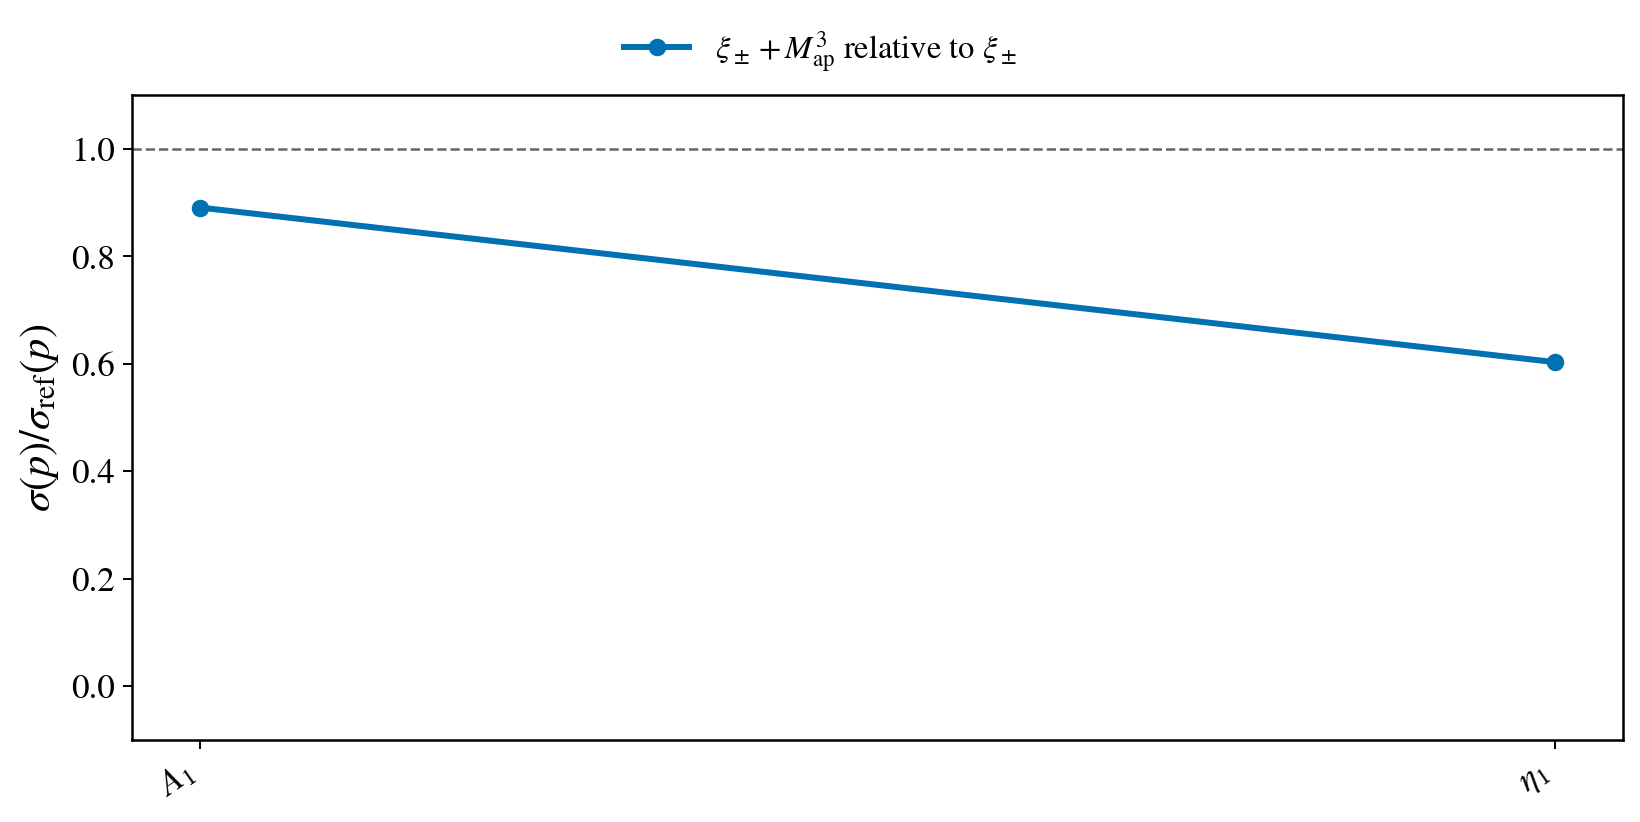

IA model: TATT


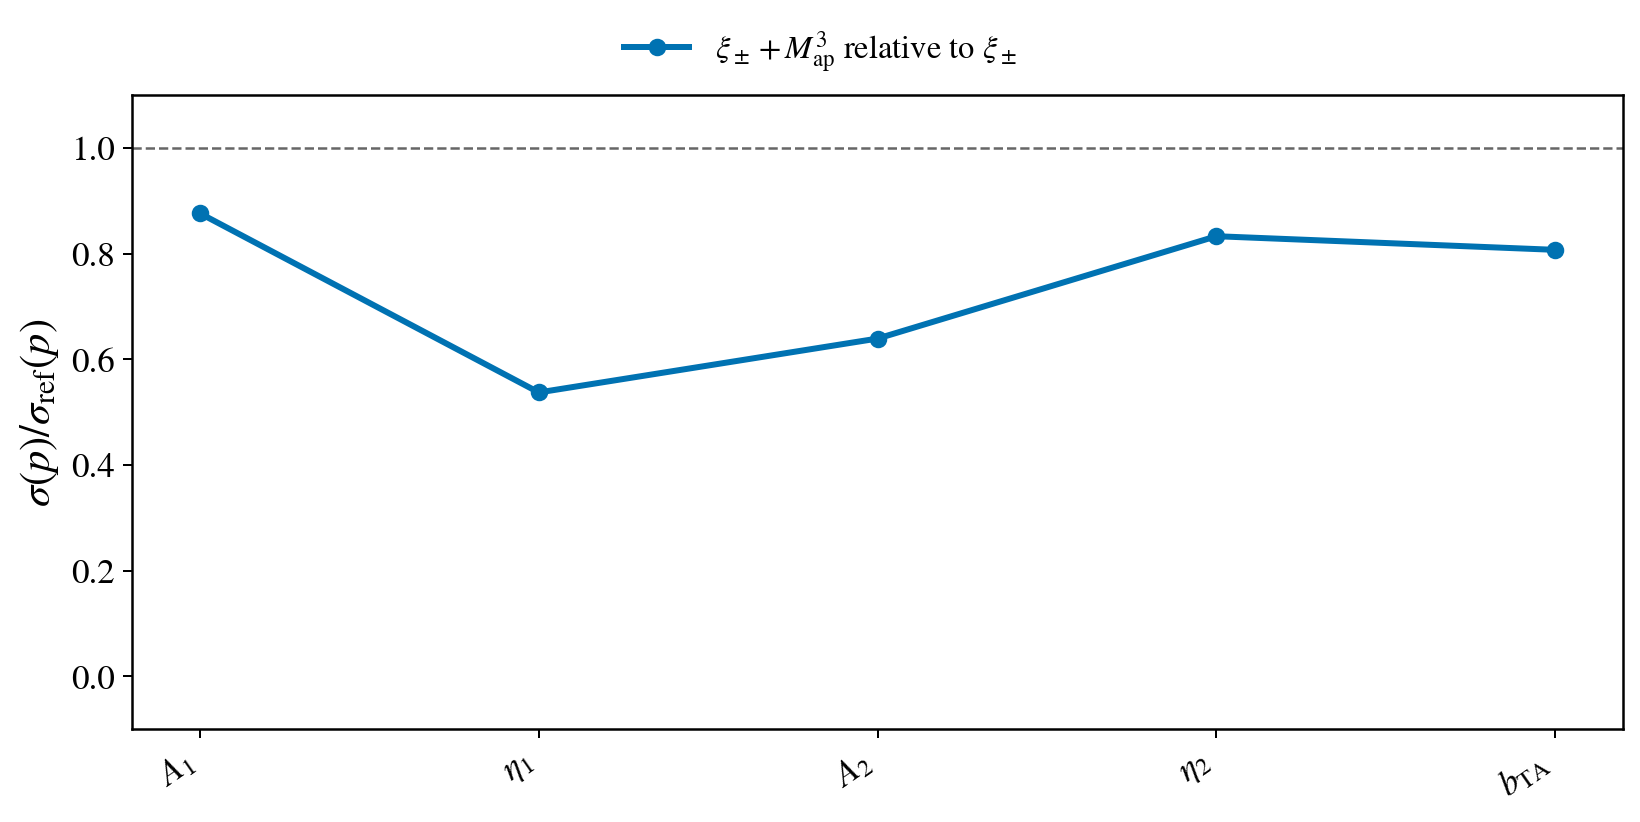

In [10]:
for model in ("nla", "tatt"):
    print("IA model:", model.upper())
    error_figure, error_axis = nw.plot_ia_errors(result=forecasts[model])
    plt.show()

### Common cosmological parameters after marginalizing IA

The contours compare joint NLA and TATT in $(\Omega_m,\sigma_8,w_0,w_a)$. The
code calculates each full covariance before picking these coordinates, because
picking a Fisher submatrix first would fix the omitted nuisance parameters and
overstate information while IA, photo-z and calibration stay uncertain. The
contours are local Gaussians without clipping at parameter bounds.

The weak dark-energy constraints push these local ellipses far beyond the
region where the Gaussian approximation is useful, including negative matter
density; those portions extrapolate local curvature rather than evaluate
physical cosmologies. Finite prior boundaries can strongly change sampled
credible regions, and no uniform prior width turns into an artificial Gaussian
precision here. The fixed-dark-energy comparison below answers a more
restricted question with the same saved derivatives.

Removed no burn in
Removed no burn in


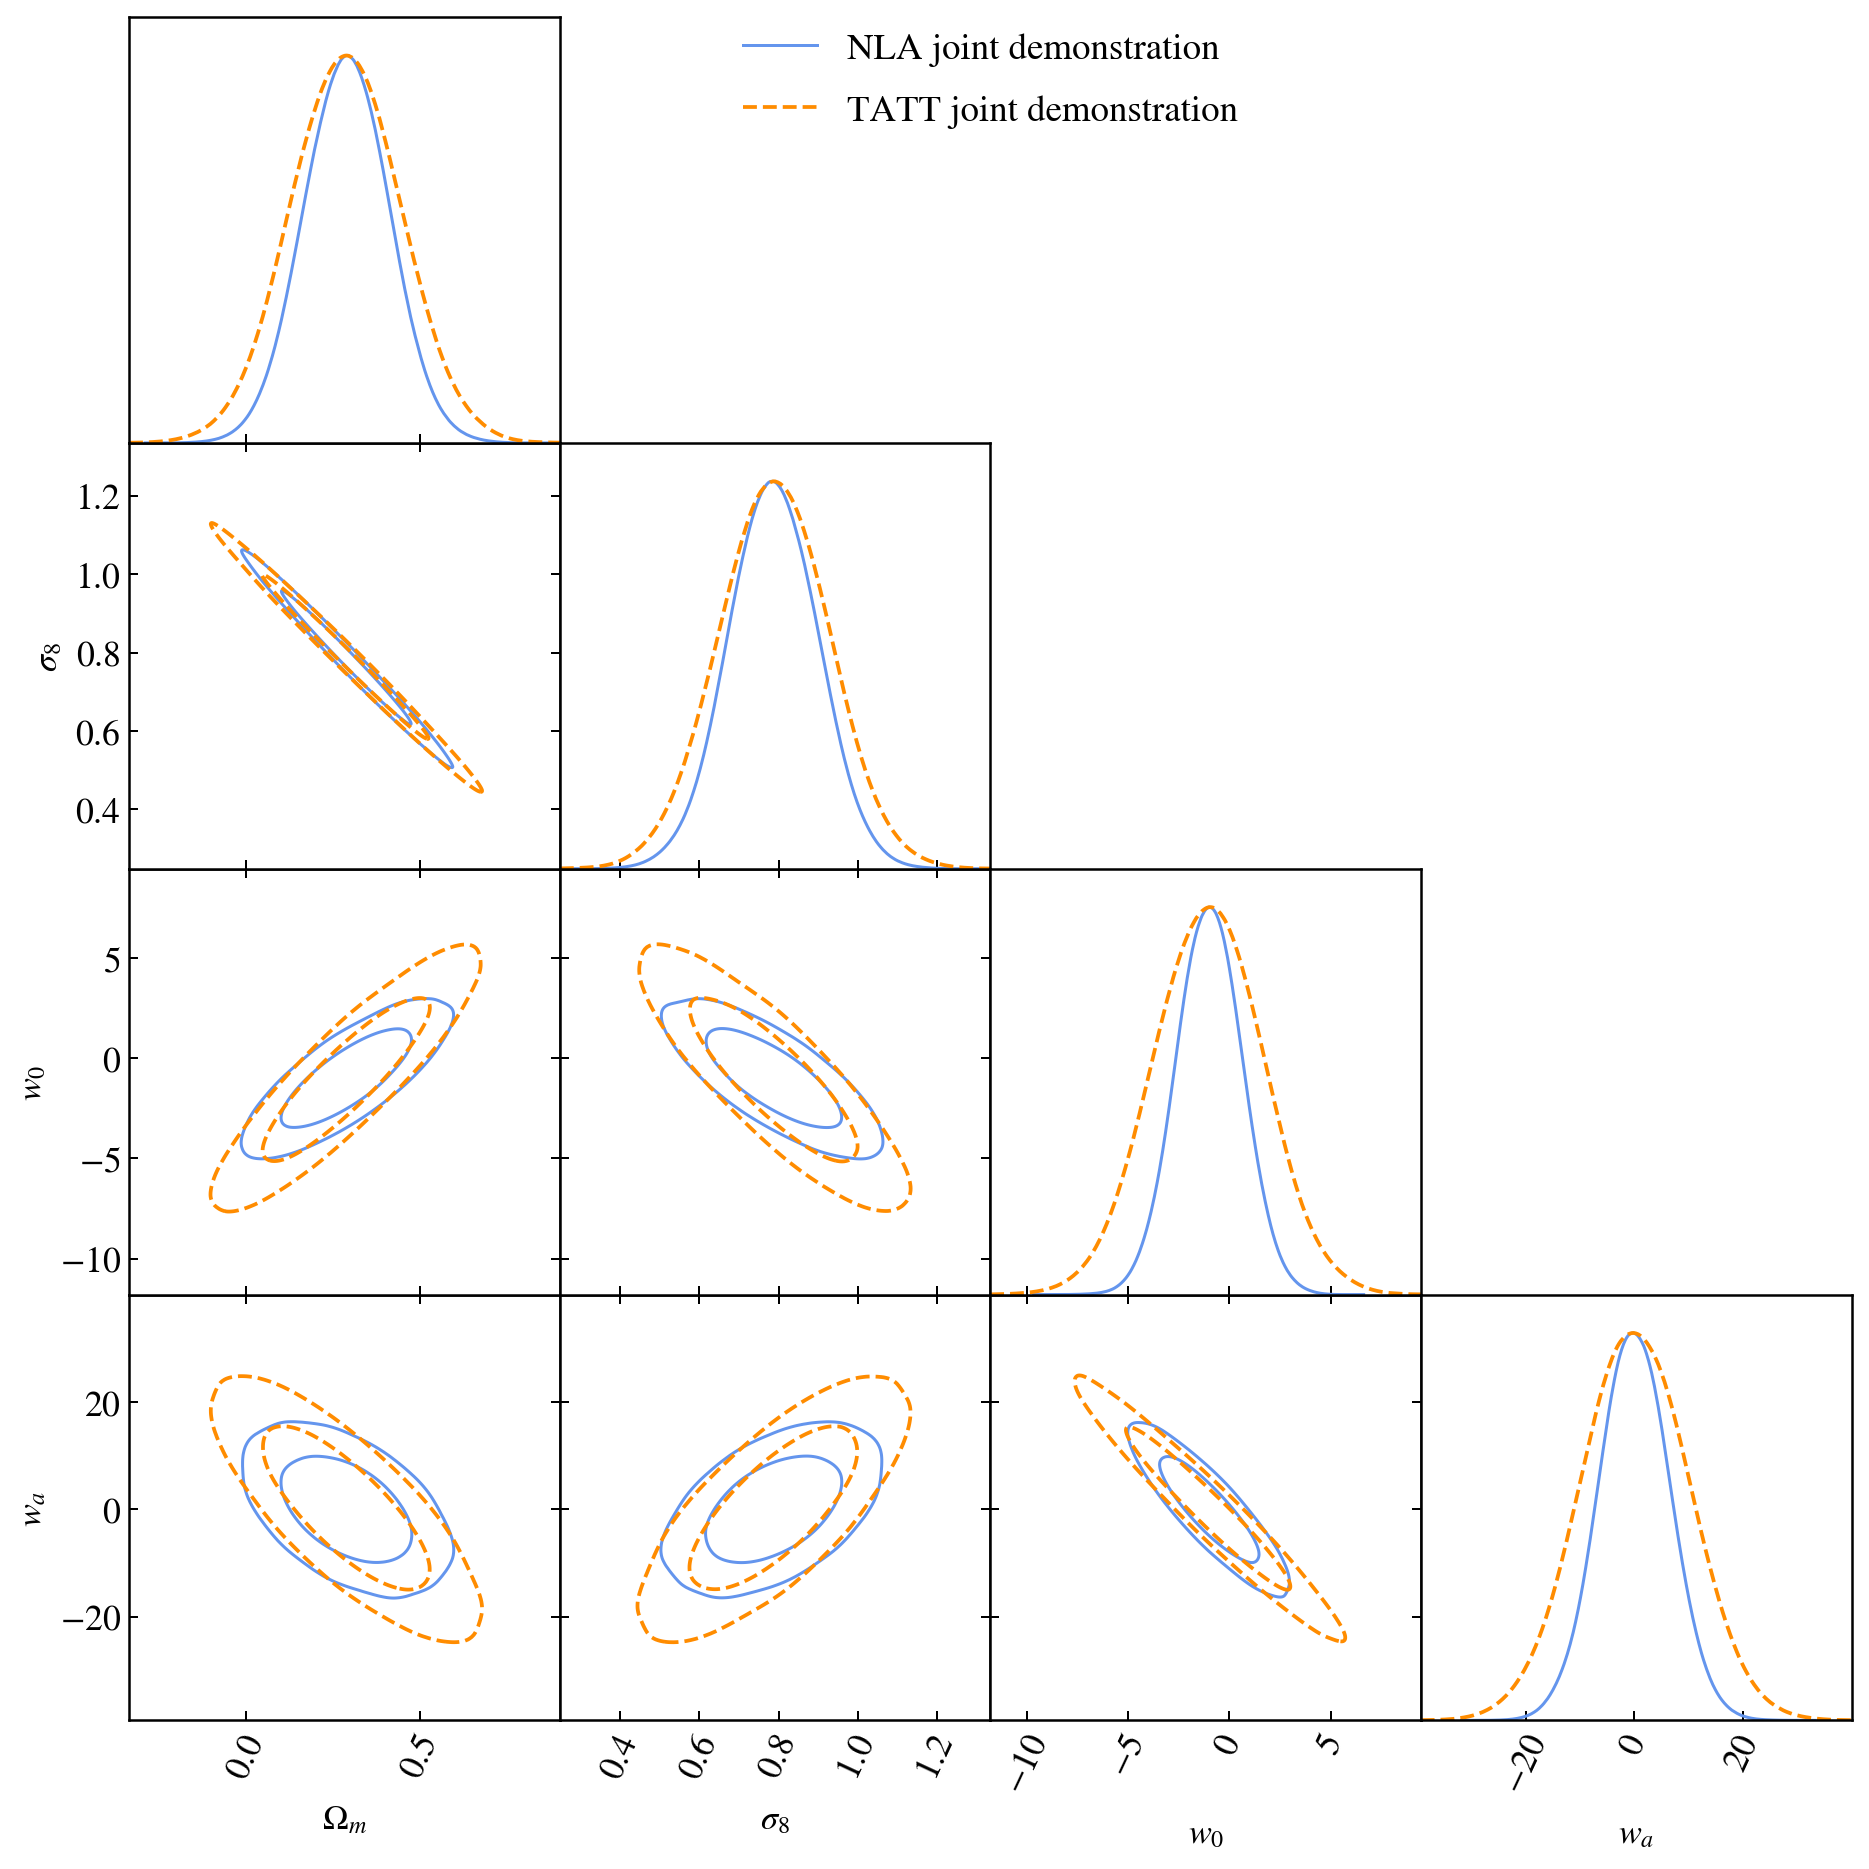

In [11]:
contours = nw.plot_common_contours(
    results=[forecasts["nla"], forecasts["tatt"]],
    metadata=[declarations["nla"], declarations["tatt"]],
    labels=["NLA joint demonstration", "TATT joint demonstration"],
    parameters=[
        "omega_m",
        "sigma8",
        "w0",
        "wa",
    ],
)
plt.show()

### A derived amplitude and within-model information gain

The common amplitude is $S_8=\sigma_8\sqrt{\Omega_m/0.3}$. Its local
covariance follows from the full marginalized $(\Omega_m,\sigma_8)$ covariance
by $C'=JCJ^{\mathsf T}$, with $\partial S_8/\partial\Omega_m=S_8/(2\Omega_m)$
and $\partial S_8/\partial\sigma_8=\sqrt{\Omega_m/0.3}$; dropping the
$\Omega_m$–$\sigma_8$ cross term would give the wrong error.

For each model, the cell reports $\sigma(S_8)$ and the joint-to-two-point
ratio of $1/\sqrt{\det C_{\Omega_m,S_8}}$. The common fiducial Jacobian
cancels from this ratio, so it equals the ratio in $(\Omega_m,\sigma_8)$.
These numbers are diagnostics of this demonstration: the papers' quoted
percentage improvements use different priors, cuts and likelihoods, and
numerical accuracy must come first before any FoM becomes a scientific
result.

In [12]:
for model in ("nla", "tatt"):
    amplitude_summary = nw.derived_amplitude_summary(
        result=forecasts[model], metadata=declarations[model],
    )
    print(model.upper(), "fiducial S8:", amplitude_summary["fiducial_s8"])
    for probe in ("two_point", "joint"):
        print(probe, "sigma(S8):", amplitude_summary[probe]["sigma_s8"])
    print("Joint / two-point (Omega_m,S8) FoM:",
          amplitude_summary["joint_over_two_point_fom"])

NLA fiducial S8: 0.772
two_point sigma(S8): 0.1119007826766509
joint sigma(S8): 0.05735797343509973
Joint / two-point (Omega_m,S8) FoM: 3.168062336210203
TATT fiducial S8: 0.772
two_point sigma(S8): 0.12401341895893955
joint sigma(S8): 0.07814357404800967
Joint / two-point (Omega_m,S8) FoM: 3.5195947226736832


### Fix dark energy while every other nuisance parameter varies

The saved Fisher matrices already describe the curvature at the fiducial
cosmology, so fixing dark energy at $w_0=-1$, $w_a=0$ needs no additional
predictions. The choice brings one assumption closer to the published
$\Lambda$CDM analysis while the demonstration's other differences stay in
place.

Separate the varied parameters into the kept set $r$ and dark energy $d$. With
$\delta d=0$, the likelihood quadratic contains only
$\delta r^{\mathsf T}F_{rr}\delta r$, so

$$\operatorname{Cov}(r\mid d\ \mathrm{fixed})=F_{rr}^{-1}.$$

Taking the Fisher submatrix before inversion is intentional here: it fixes
those two parameters, while taking the block of $F^{-1}$ would marginalize
over them instead. The code still inverts the entire kept matrix before
picking $(\Omega_m,\sigma_8)$, so IA, photo-z, shear calibration and the
other cosmological parameters stay marginalized; the saved posterior Fisher
matrices already contain their Gaussian priors once, and this calculation
adds none.

These are local Gaussian information gains with the same full 480 rows, source
reconstruction, finite triangle estimator and fixed covariance. They are not
the papers' posterior gains, they still need numerical convergence tests, and
fixing dark energy cannot correct a mismatched estimator or move the
derivatives to a different fiducial point.

In [13]:
for model in ("nla", "tatt"):
    fixed_summary = nw.fixed_dark_energy_summary(
        result=forecasts[model],
        metadata=declarations[model],
    )
    print(model.upper(), "fixed parameters:", fixed_summary["fixed_parameters"])
    print("Still marginalized:", fixed_summary["marginalized_parameters"])
    for probe in ("two_point", "joint"):
        print(probe, "sigma(S8):", fixed_summary[probe]["sigma_s8"])
        print(probe, "IA errors:", fixed_summary[probe]["sigma_ia"])
    print("Joint / two-point (Omega_m,S8) FoM:",
          fixed_summary["joint_over_two_point_fom"])


NLA fixed parameters: {'w0': -1.0, 'wa': 0.0}
Still marginalized: ['omega_m', 'sigma8', 'omega_b', 'h', 'ns', 'a1', 'eta1', 'm1', 'm2', 'm3', 'm4', 'dz1', 'dz2', 'dz3', 'dz4']
two_point sigma(S8): 0.019218567154718216
two_point IA errors: {'a1': 1.038511865166578, 'eta1': 9.083664224140328}
joint sigma(S8): 0.015464657817573136
joint IA errors: {'a1': 0.8991727103821935, 'eta1': 7.93251575468463}
Joint / two-point (Omega_m,S8) FoM: 2.138926103835772
TATT fixed parameters: {'w0': -1.0, 'wa': 0.0}
Still marginalized: ['omega_m', 'sigma8', 'omega_b', 'h', 'ns', 'a1', 'eta1', 'a2', 'eta2', 'bta', 'm1', 'm2', 'm3', 'm4', 'dz1', 'dz2', 'dz3', 'dz4']
two_point sigma(S8): 0.021963609457819173
two_point IA errors: {'a1': 0.9724413233768744, 'eta1': 7.066498590335221, 'a2': 0.646649891252282, 'eta2': 4.446597393104851, 'bta': 3.3415343291358206}
joint sigma(S8): 0.01550683829504266
joint IA errors: {'a1': 0.8555670923794118, 'eta1': 5.398272519948479, 'a2': 0.5577573552877454, 'eta2': 3.93402994

## 6. Interpret the result with its assumptions

A smaller IA error or a changed degeneracy direction is the local prediction
of this mean and covariance. It does not establish baryon insensitivity, exact
agreement with the public aperture estimator, or the adequacy of omitting
nonlinear-IA covariance changes: all 400 two-point rows include scales the
published analysis removes, and both mean models reuse the public covariance
without connected TATT covariance responses.

Before quoting an improvement, use
[EXAMPLE_FISHER_ACCURACY.ipynb](EXAMPLE_FISHER_ACCURACY.ipynb) to inspect
numerical noise and refine the mean independently of derivative steps, match
the triangle support and averaging to the measurement, apply explicit
scientific cuts, and examine the remaining physical assumptions.
Finite-simulation precision corrections also need an independent realization
structure rather than a patch count;
[EXAMPLE_COVARIANCE_PME.ipynb](EXAMPLE_COVARIANCE_PME.ipynb) develops that
issue.